# Reproducible Transfer Learning and Model Soup for 3-Class Image Classification

This notebook trains and evaluates **ConvNeXt, DenseNet, ResNet, MobileNet, and Swin-T** on the following directory layout:

```text
data_cnn/
├── HOP/
├── VI/
└── VIEN/
```

It is designed for Google Colab, but also runs in a normal Jupyter environment. The workflow is intentionally strict:

- one persisted, stratified split is shared by every experiment;
- exact duplicate files are excluded before splitting to reduce leakage risk;
- checkpoint selection and model-soup construction use **validation data only**;
- the test set is used only in the final evaluation section;
- completed test experiments are identified in `results/results.csv` and are not evaluated again when the final cell is rerun.

> **Before running:** place the three class folders under `PROJECT_ROOT/Data`. The configuration cell automatically checks common Colab locations. Pretrained ImageNet weights require internet access the first time they are downloaded.

## 1. Environment Setup

Only missing Python packages are installed; PyTorch itself is not upgraded automatically because changing the Colab CUDA/PyTorch pairing can break GPU support.

In [1]:
import importlib.util
import os
import platform
import subprocess
import sys

REQUIRED_PACKAGES = {
    "numpy": "numpy",
    "pandas": "pandas",
    "PIL": "pillow",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "tqdm": "tqdm",
}
missing = [pip_name for module_name, pip_name in REQUIRED_PACKAGES.items()
           if importlib.util.find_spec(module_name) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pillow-heif"])
    from pillow_heif import register_heif_opener
    register_heif_opener()
if importlib.util.find_spec("torch") is None or importlib.util.find_spec("torchvision") is None:
    raise ImportError(
        "PyTorch and torchvision are required. In Colab choose Runtime > Change runtime type and rerun; "
        "outside Colab, install a mutually compatible build from https://pytorch.org/get-started/."
    )

import copy
import gc
import hashlib
import json
import math
import random
import re
import time
import uuid
from contextlib import nullcontext
from dataclasses import asdict, dataclass, field
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Dict, Iterable, List, Mapping, Optional, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from PIL import Image, ImageFile, UnidentifiedImageError
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
)
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from torch import nn
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import models, transforms
from torchvision.transforms import InterpolationMode
from tqdm.auto import tqdm

import torch
import torchvision

ImageFile.LOAD_TRUNCATED_IMAGES = False
sns.set_theme(style="whitegrid", context="notebook")

IN_COLAB = "google.colab" in sys.modules
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Python version     : {platform.python_version()}")
print(f"PyTorch version    : {torch.__version__}")
print(f"torchvision version: {torchvision.__version__}")
print(f"CUDA runtime       : {torch.version.cuda}")
print(f"Selected device    : {DEVICE}")
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print(f"GPU name           : {torch.cuda.get_device_name(0)}")
    print(f"GPU memory         : {props.total_memory / 1024**3:.2f} GiB")
else:
    print("GPU name/memory    : not available (CPU execution will be slow)")

Python version     : 3.13.15
PyTorch version    : 2.11.0+cu130
torchvision version: 0.26.0+cu130
CUDA runtime       : 13.0
Selected device    : cuda
GPU name           : Tesla T4
GPU memory         : 14.56 GiB


### Optional: mount Google Drive

Uncomment the next cell if the project is stored in Drive, then set the `PROJECT_ROOT` environment variable (for example, `/content/drive/MyDrive/project`) **before** running the configuration cell.

In [2]:
import shutil
from google.colab import drive
drive.mount('/content/drive')

SRC = '/content/drive/MyDrive/data_cnn'
DST = '/content/project/Data'

if not os.path.isdir(DST):
    os.makedirs('/content/project', exist_ok=True)
    shutil.copytree(SRC, DST)
    print("Đã copy dữ liệu về ổ đĩa Colab.")
else:
    print("Dữ liệu cục bộ đã có, bỏ qua bước copy.")

os.environ['PROJECT_ROOT'] = '/content/project'
os.environ['OUTPUT_ROOT'] = '/content/drive/MyDrive/project_outputs'
print(sorted(os.listdir(DST)))

Mounted at /content/drive
Đã copy dữ liệu về ổ đĩa Colab.
['HOP', 'VI', 'VIEN']


## 2. Configuration

All frequently changed settings live in one dataclass. `MODEL_NAME` is useful for a single-model run; `MODELS_TO_TRAIN` controls the standard multi-model experiment. Per-model batch-size overrides reduce out-of-memory risk on typical Colab GPUs.

In [3]:
@dataclass
class Config:
    # Required experiment controls
    SEED: int = 43
    IMAGE_SIZE: int = 224
    BATCH_SIZE: int = 32
    NUM_EPOCHS: int = 25
    LEARNING_RATE: float = 1e-4       # classification-head learning rate
    BACKBONE_LEARNING_RATE: float = 1e-5
    WEIGHT_DECAY: float = 5e-2
    NUM_WORKERS: int = 2
    EARLY_STOPPING_PATIENCE: int = 6
    MODEL_NAME: str = "ConvNeXt"
    PRETRAINED: bool = True
    USE_AMP: bool = True
    TOP_K_CHECKPOINTS: int = 5

    # Models and memory-conscious overrides
    MODELS_TO_TRAIN: Tuple[str, ...] = ("ConvNeXt", "DenseNet", "ResNet", "MobileNet", "SwinT")
    MODEL_BATCH_SIZES: Dict[str, int] = field(default_factory=lambda: {
        "ConvNeXt": 24, "DenseNet": 24, "ResNet": 32, "MobileNet": 48, "SwinT": 16
    })

    # Split policy. VAL_SIZE and TEST_SIZE are fractions of the full unique valid dataset.
    VAL_SIZE: float = 0.15
    TEST_SIZE: float = 0.15

    # Training controls
    FREEZE_BACKBONE: bool = True
    UNFREEZE_EPOCH: Optional[int] = 3  # e.g. 3; only meaningful when FREEZE_BACKBONE=True
    GRADIENT_ACCUMULATION_STEPS: int = 1
    MAX_GRAD_NORM: Optional[float] = 1.0
    LABEL_SMOOTHING: float = 0.1
    LR_SCHEDULER_FACTOR: float = 0.5
    LR_SCHEDULER_PATIENCE: int = 1
    EARLY_STOPPING_MIN_DELTA: float = 1e-4
    CHECKPOINT_INTERVAL: int = 5

    # Choose exactly one: "weighted_loss", "weighted_sampler", "minority_augmentation", "none".
    IMBALANCE_STRATEGY: str = "weighted_loss"
    MINORITY_EXTRA_AUGMENT_PROB: float = 0.50

    # Runtime controls
    PIN_MEMORY: bool = True
    PERSISTENT_WORKERS: bool = True
    SAVE_OPTIMIZER_STATE: bool = False  # True enables full resume but substantially increases disk use
    RUN_TRAINING: bool = True
    RUN_MODEL_SOUP: bool = True
    GREEDY_SOUP_MIN_DELTA: float = 0.0

    # Dataset definition
    CLASS_NAMES: Tuple[str, ...] = ("HOP", "VI", "VIEN")
    VALID_EXTENSIONS: Tuple[str, ...] = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp")

cfg = Config()

# Locate an existing Data folder unless PROJECT_ROOT was explicitly supplied.
def resolve_project_root() -> Path:
    explicit = os.environ.get("PROJECT_ROOT")
    if explicit:
        return Path(explicit).expanduser().resolve()
    candidates = []
    if IN_COLAB:
        candidates += [Path("/content/project"), Path("/content")]
    candidates += [Path.cwd() / "project", Path.cwd()]
    for candidate in candidates:
        if all((candidate / "Data" / name).is_dir() for name in cfg.CLASS_NAMES):
            return candidate.resolve()
    return (Path("/content/project") if IN_COLAB else Path.cwd() / "project").resolve()

PROJECT_ROOT = resolve_project_root()
OUTPUT_ROOT = Path(os.environ.get("OUTPUT_ROOT", str(PROJECT_ROOT)))
DATA_ROOT = PROJECT_ROOT / "Data"
CHECKPOINT_ROOT = OUTPUT_ROOT / "checkpoints"
RESULTS_ROOT = OUTPUT_ROOT / "results"
FIGURE_ROOT = RESULTS_ROOT / "figures"
PREDICTION_ROOT = RESULTS_ROOT / "predictions"
METRICS_ROOT = RESULTS_ROOT / "metrics"

for path in [DATA_ROOT, CHECKPOINT_ROOT, RESULTS_ROOT, FIGURE_ROOT, PREDICTION_ROOT, METRICS_ROOT]:
    path.mkdir(parents=True, exist_ok=True)
for class_name in cfg.CLASS_NAMES:
    (DATA_ROOT / class_name).mkdir(parents=True, exist_ok=True)
for model_name in cfg.MODELS_TO_TRAIN:
    (CHECKPOINT_ROOT / model_name).mkdir(parents=True, exist_ok=True)


def json_safe(value: Any) -> Any:
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return float(value)
    if isinstance(value, np.ndarray):
        return value.tolist()
    return value

CONFIG_DICT = json_safe(asdict(cfg))
print(f"Project root : {PROJECT_ROOT}")
print(f"Dataset root : {DATA_ROOT}")
print(f"Results root : {RESULTS_ROOT}")
print(json.dumps(CONFIG_DICT, indent=2))

Project root : /content/project
Dataset root : /content/project/Data
Results root : /content/drive/MyDrive/project_outputs/results
{
  "SEED": 43,
  "IMAGE_SIZE": 224,
  "BATCH_SIZE": 32,
  "NUM_EPOCHS": 25,
  "LEARNING_RATE": 0.0001,
  "BACKBONE_LEARNING_RATE": 1e-05,
  "WEIGHT_DECAY": 0.05,
  "NUM_WORKERS": 2,
  "EARLY_STOPPING_PATIENCE": 6,
  "MODEL_NAME": "ConvNeXt",
  "PRETRAINED": true,
  "USE_AMP": true,
  "TOP_K_CHECKPOINTS": 5,
  "MODELS_TO_TRAIN": [
    "ConvNeXt",
    "DenseNet",
    "ResNet",
    "MobileNet",
    "SwinT"
  ],
  "MODEL_BATCH_SIZES": {
    "ConvNeXt": 24,
    "DenseNet": 24,
    "ResNet": 32,
    "MobileNet": 48,
    "SwinT": 16
  },
  "VAL_SIZE": 0.15,
  "TEST_SIZE": 0.15,
  "FREEZE_BACKBONE": true,
  "UNFREEZE_EPOCH": 3,
  "GRADIENT_ACCUMULATION_STEPS": 1,
  "MAX_GRAD_NORM": 1.0,
  "LABEL_SMOOTHING": 0.1,
  "LR_SCHEDULER_FACTOR": 0.5,
  "LR_SCHEDULER_PATIENCE": 1,
  "EARLY_STOPPING_MIN_DELTA": 0.0001,
  "CHECKPOINT_INTERVAL": 5,
  "IMBALANCE_STRATEGY": "wei

## 3. Reproducibility / Seed

Determinism is enabled for Python, NumPy, PyTorch, CUDA, and DataLoader workers. Deterministic CUDA algorithms can be slower and may raise an error if an operation has no deterministic implementation. Setting `CUBLAS_WORKSPACE_CONFIG` before CUDA work and disabling cuDNN benchmarking favor repeatability over maximum throughput. Exact bitwise equality can still vary across PyTorch/CUDA versions and hardware.

In [4]:
os.environ.setdefault("PYTHONHASHSEED", str(cfg.SEED))
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")


def set_global_seed(seed: int, deterministic: bool = True) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    if deterministic:
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True
        try:
            torch.use_deterministic_algorithms(True, warn_only=True)
        except TypeError:  # compatibility with older PyTorch
            torch.use_deterministic_algorithms(True)


def seed_worker(worker_id: int) -> None:
    # torch.initial_seed() already includes worker_id and the DataLoader generator state.
    worker_seed = torch.initial_seed() % (2**32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def seeded_generator(seed: int) -> torch.Generator:
    generator = torch.Generator()
    generator.manual_seed(seed)
    return generator

set_global_seed(cfg.SEED)
print(f"Central random seed set to {cfg.SEED}")

Central random seed set to 43


## 4. Dataset Analysis

The scanner verifies every supported image with Pillow, fully decodes it as RGB, records dimensions and SHA-256 content hashes, and reports unsupported or invalid files. Exact same-label duplicates are excluded from the modeling manifest (without deleting files). Identical content assigned to different classes is treated as a label conflict and stops the notebook.

In [5]:
def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        while chunk := handle.read(chunk_size):
            digest.update(chunk)
    return digest.hexdigest()


def inspect_image(path: Path) -> Dict[str, Any]:
    try:
        if path.stat().st_size == 0:
            raise ValueError("empty file")
        with Image.open(path) as image:
            image.verify()
        with Image.open(path) as image:
            rgb = image.convert("RGB")
            rgb.load()  # force full decoding
            width, height = rgb.size
            image_format = image.format or path.suffix.lstrip(".").upper()
        if width <= 0 or height <= 0:
            raise ValueError("non-positive dimensions")
        return {
            "is_valid": True,
            "error": "",
            "width": width,
            "height": height,
            "format": image_format,
            "file_size_bytes": path.stat().st_size,
            "sha256": sha256_file(path),
        }
    except (UnidentifiedImageError, OSError, ValueError, SyntaxError) as exc:
        return {
            "is_valid": False,
            "error": f"{type(exc).__name__}: {exc}",
            "width": np.nan,
            "height": np.nan,
            "format": "",
            "file_size_bytes": path.stat().st_size if path.exists() else np.nan,
            "sha256": "",
        }


def scan_dataset(data_root: Path) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    valid_rows: List[Dict[str, Any]] = []
    invalid_rows: List[Dict[str, Any]] = []
    class_to_idx = {name: idx for idx, name in enumerate(cfg.CLASS_NAMES)}

    for class_name in cfg.CLASS_NAMES:
        class_dir = data_root / class_name
        files = sorted(path for path in class_dir.rglob("*") if path.is_file())
        for path in tqdm(files, desc=f"Scanning {class_name}"):
            rel_parts = path.relative_to(class_dir).parts
            group_id = f"{class_name}/{rel_parts[0]}" if len(rel_parts) > 1 else f"{class_name}/{path.stem}"
            base = {
                "relative_path": path.relative_to(PROJECT_ROOT).as_posix(),
                "class_name": class_name,
                "label": class_to_idx[class_name],
                "group": group_id,
            }
            if path.suffix.lower() not in cfg.VALID_EXTENSIONS:
                invalid_rows.append({**base, "error": f"unsupported extension: {path.suffix}"})
                continue
            info = inspect_image(path)
            row = {**base, **info}
            if info["is_valid"]:
                valid_rows.append(row)
            else:
                invalid_rows.append(row)

    valid_df = pd.DataFrame(valid_rows)
    invalid_df = pd.DataFrame(invalid_rows)
    if valid_df.empty:
        raise FileNotFoundError(
            f"No valid images were found under {data_root}. "
            "Place images in Data/HOP, Data/VI, and Data/VIEN, then rerun this section."
        )

    # Detect label conflicts before excluding duplicate copies.
    conflicts = valid_df.groupby("sha256")["class_name"].nunique()
    conflict_hashes = conflicts[conflicts > 1].index.tolist()
    duplicate_mask = valid_df.duplicated("sha256", keep="first")
    duplicates_df = valid_df.loc[duplicate_mask].copy()
    if not duplicates_df.empty:
        first_path_by_hash = valid_df.drop_duplicates("sha256").set_index("sha256")["relative_path"]
        duplicates_df["kept_relative_path"] = duplicates_df["sha256"].map(first_path_by_hash)
    if conflict_hashes:
        conflict_rows = valid_df[valid_df["sha256"].isin(conflict_hashes)]
        conflict_rows.to_csv(METRICS_ROOT / "label_conflicts.csv", index=False)
        raise ValueError(
            "Identical image content appears under different class labels. "
            f"Resolve the conflicts listed in {METRICS_ROOT / 'label_conflicts.csv'}."
        )

    unique_valid_df = valid_df.loc[~duplicate_mask].copy().reset_index(drop=True)
    return unique_valid_df, invalid_df, duplicates_df


manifest_df, invalid_images_df, duplicate_images_df = scan_dataset(DATA_ROOT)
manifest_df.to_csv(METRICS_ROOT / "dataset_manifest_unique_valid.csv", index=False)
invalid_images_df.to_csv(METRICS_ROOT / "invalid_images.csv", index=False)
duplicate_images_df.to_csv(METRICS_ROOT / "excluded_exact_duplicates.csv", index=False)

class_counts_before = manifest_df["class_name"].value_counts().reindex(cfg.CLASS_NAMES, fill_value=0)
invalid_counts = (
    invalid_images_df["class_name"].value_counts().reindex(cfg.CLASS_NAMES, fill_value=0)
    if not invalid_images_df.empty else pd.Series(0, index=cfg.CLASS_NAMES)
)
duplicate_counts = (
    duplicate_images_df["class_name"].value_counts().reindex(cfg.CLASS_NAMES, fill_value=0)
    if not duplicate_images_df.empty else pd.Series(0, index=cfg.CLASS_NAMES)
)
scan_summary = pd.DataFrame({
    "unique_valid_images": class_counts_before,
    "excluded_exact_duplicates": duplicate_counts,
    "invalid_or_unsupported": invalid_counts,
})
scan_summary["all_discovered_files"] = scan_summary.sum(axis=1)
scan_summary.to_csv(METRICS_ROOT / "dataset_scan_summary.csv")
print("Dataset scan summary by class:")
display(scan_summary)
print(f"Invalid/unsupported files: {len(invalid_images_df)}")
print(f"Excluded exact duplicates: {len(duplicate_images_df)}")
if not invalid_images_df.empty:
    display(invalid_images_df[["relative_path", "class_name", "error"]].head(20))

Scanning HOP:   0%|          | 0/716 [00:00<?, ?it/s]

Scanning VI:   0%|          | 0/717 [00:00<?, ?it/s]

Scanning VIEN:   0%|          | 0/1254 [00:00<?, ?it/s]

Dataset scan summary by class:


,unique_valid_images,excluded_exact_duplicates,invalid_or_unsupported,all_discovered_files
HOP,716,0,0,716
VI,713,4,0,717
VIEN,1250,4,0,1254


Invalid/unsupported files: 0
Excluded exact duplicates: 8


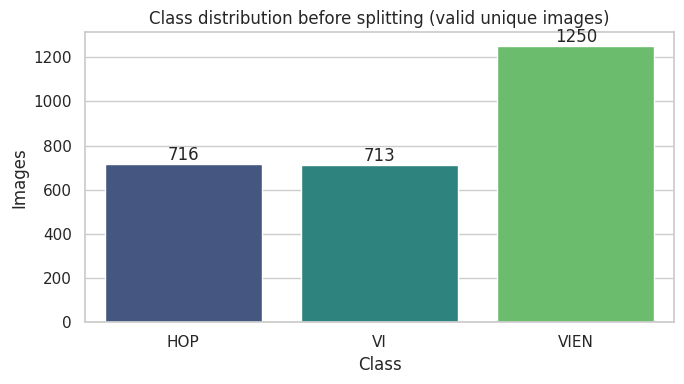

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=class_counts_before.index, y=class_counts_before.values, ax=ax, palette="viridis", hue=class_counts_before.index, legend=False)
ax.set(title="Class distribution before splitting (valid unique images)", xlabel="Class", ylabel="Images")
for index, value in enumerate(class_counts_before.values):
    ax.text(index, value, str(value), ha="center", va="bottom")
fig.tight_layout()
fig.savefig(FIGURE_ROOT / "class_distribution_before_split.png", dpi=160, bbox_inches="tight")
plt.show()

### Representative samples

Sampling is seeded. Images are shown in their original aspect ratio and are not augmented in this figure.

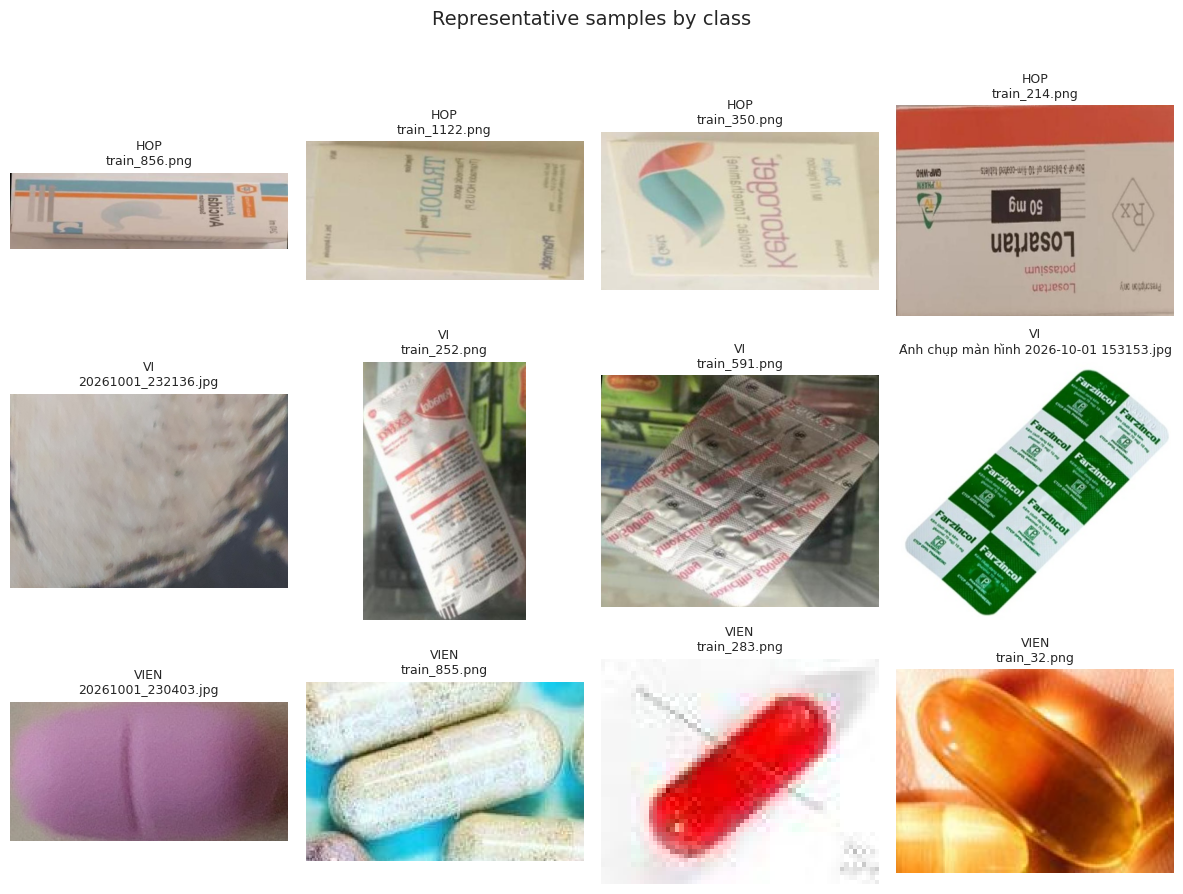

In [7]:
def show_class_samples(frame: pd.DataFrame, samples_per_class: int = 4) -> None:
    rng = np.random.default_rng(cfg.SEED)
    rows = len(cfg.CLASS_NAMES)
    fig, axes = plt.subplots(rows, samples_per_class, figsize=(3 * samples_per_class, 3 * rows), squeeze=False)
    for row_index, class_name in enumerate(cfg.CLASS_NAMES):
        candidates = frame[frame["class_name"] == class_name]
        chosen = candidates.iloc[rng.choice(len(candidates), size=min(samples_per_class, len(candidates)), replace=False)]
        for column_index in range(samples_per_class):
            ax = axes[row_index, column_index]
            ax.axis("off")
            if column_index < len(chosen):
                record = chosen.iloc[column_index]
                with Image.open(PROJECT_ROOT / record["relative_path"]) as image:
                    ax.imshow(image.convert("RGB"))
                ax.set_title(f"{class_name}\n{Path(record['relative_path']).name}", fontsize=9)
    fig.suptitle("Representative samples by class", y=1.01, fontsize=14)
    fig.tight_layout()
    fig.savefig(FIGURE_ROOT / "representative_samples.png", dpi=160, bbox_inches="tight")
    plt.show()

show_class_samples(manifest_df)

## 5. Train / Validation / Test Split

A two-stage stratified split creates train, validation, and test subsets. The CSV stores the relative path, label, and content hash. If that file already exists, it is reused only when it exactly matches the current unique-valid manifest; otherwise the notebook stops rather than silently changing samples.

In [8]:
SPLIT_PATH = METRICS_ROOT / f"data_splits_seed_{cfg.SEED}.csv"


def create_or_load_splits(frame: pd.DataFrame) -> pd.DataFrame:
    identity_columns = ["relative_path", "sha256", "class_name", "label", "group"]
    current = frame[identity_columns].copy().sort_values("relative_path").reset_index(drop=True)

    if SPLIT_PATH.exists():
        saved = pd.read_csv(SPLIT_PATH)
        required = set(identity_columns + ["split"])
        if not required.issubset(saved.columns):
            raise ValueError(f"Existing split file lacks required columns: {required - set(saved.columns)}")
        saved_identity = saved[identity_columns].sort_values("relative_path").reset_index(drop=True)
        if not current.equals(saved_identity):
            raise RuntimeError(
                f"Dataset content differs from the persisted split at {SPLIT_PATH}. "
                "To intentionally create a new split, archive/rename that CSV first."
            )
        print(f"Reusing persisted split: {SPLIT_PATH}")
        return saved

    if not (0 < cfg.VAL_SIZE < 1 and 0 < cfg.TEST_SIZE < 1 and cfg.VAL_SIZE + cfg.TEST_SIZE < 1):
        raise ValueError("VAL_SIZE and TEST_SIZE must be positive and sum to less than 1.")
    if (current.groupby("class_name").size() < 3).any():
        raise ValueError("Each class needs at least 3 valid unique images for train/validation/test splitting.")

        # Random split (không stratify, không group): 70% train / 15% val / 15% test
    train_val, test = train_test_split(
        current, test_size=cfg.TEST_SIZE, random_state=cfg.SEED, shuffle=True, stratify=None
    )
    val_fraction = cfg.VAL_SIZE / (1.0 - cfg.TEST_SIZE)   # 0.15 / 0.85
    train, val = train_test_split(
        train_val, test_size=val_fraction, random_state=cfg.SEED, shuffle=True, stratify=None
    )

    train = train.assign(split="train")
    val = val.assign(split="val")
    test = test.assign(split="test")
    split_frame = pd.concat([train, val, test], ignore_index=True).sort_values("relative_path").reset_index(drop=True)
    assert split_frame.groupby("sha256")["split"].nunique().max() == 1, "Content-hash leakage detected."
    # Since exact duplicates were removed, a hash can occur in only one split. Keep the assertion explicit.
    ct = pd.crosstab(split_frame["class_name"], split_frame["split"])
    assert set(ct.columns) == {"train", "val", "test"} and (ct > 0).all().all(), \
    f"Có lớp bị thiếu trong một split:\n{ct}"
    split_frame.to_csv(SPLIT_PATH, index=False)
    print(f"Saved reproducible split to {SPLIT_PATH}")
    return split_frame


split_df = create_or_load_splits(manifest_df)
with SPLIT_PATH.open("rb") as handle:
    SPLIT_FINGERPRINT = hashlib.sha256(handle.read()).hexdigest()

split_distribution = pd.crosstab(split_df["class_name"], split_df["split"]).reindex(index=cfg.CLASS_NAMES, columns=["train", "val", "test"], fill_value=0)
display(split_distribution)
print(f"Split fingerprint: {SPLIT_FINGERPRINT[:16]}...")

class_mapping = {name: index for index, name in enumerate(cfg.CLASS_NAMES)}
with (METRICS_ROOT / "class_mapping.json").open("w") as handle:
    json.dump(class_mapping, handle, indent=2)

Saved reproducible split to /content/drive/MyDrive/project_outputs/results/metrics/data_splits_seed_43.csv


split,train,val,test
class_name,,,
HOP,497,117,102
VI,492,115,106
VIEN,886,170,194


Split fingerprint: 5779038e7a68a089...


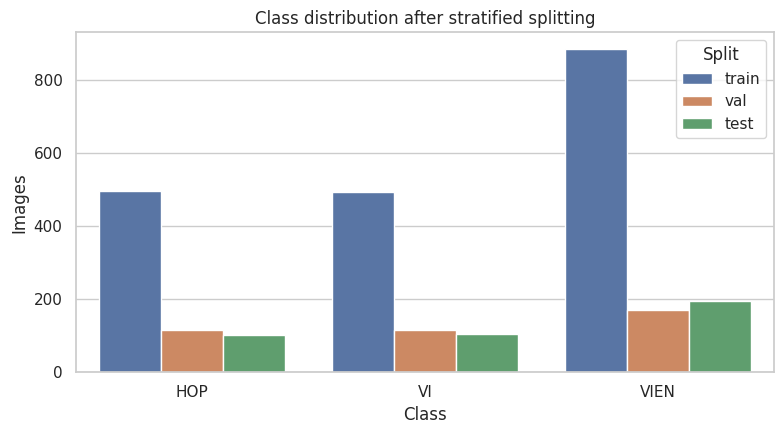

In [9]:
plot_frame = split_distribution.reset_index().melt(id_vars="class_name", var_name="Split", value_name="Images")
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=plot_frame, x="class_name", y="Images", hue="Split", ax=ax)
ax.set(title="Class distribution after stratified splitting", xlabel="Class", ylabel="Images")
fig.tight_layout()
fig.savefig(FIGURE_ROOT / "class_distribution_after_split.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. Data Preprocessing

All selected torchvision ImageNet checkpoints use RGB inputs normalized with ImageNet mean and standard deviation. Training uses a moderate random resized crop, horizontal flip, small rotation, and restrained color jitter. Validation and test preprocessing are deterministic.

In [10]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
RESIZE_SIZE = int(round(cfg.IMAGE_SIZE * 256 / 224))

train_transform = transforms.Compose([
   transforms.RandomResizedCrop(cfg.IMAGE_SIZE, scale=(0.5, 1.0), ratio=(0.75, 1.33),
                                 interpolation=InterpolationMode.BICUBIC, antialias=True),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15, interpolation=InterpolationMode.BILINEAR),
    transforms.RandomApply([transforms.ColorJitter(0.3, 0.3, 0.2, 0.03)], p=0.7),
    transforms.RandomApply([transforms.GaussianBlur(5, sigma=(0.1, 1.5))], p=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.15)),
])

eval_transform = transforms.Compose([
    transforms.Resize(RESIZE_SIZE, interpolation=InterpolationMode.BICUBIC, antialias=True),
    transforms.CenterCrop(cfg.IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Used only when IMBALANCE_STRATEGY == "minority_augmentation".
minority_extra_transform = transforms.RandomApply([
    transforms.Compose([
        transforms.RandomAffine(degrees=5, translate=(0.03, 0.03), scale=(0.96, 1.04),
                                interpolation=InterpolationMode.BILINEAR),
        transforms.ColorJitter(brightness=0.08, contrast=0.08),
    ])
], p=cfg.MINORITY_EXTRA_AUGMENT_PROB)


class ManifestDataset(Dataset):
    def __init__(
        self,
        frame: pd.DataFrame,
        transform: transforms.Compose,
        training: bool = False,
        minority_classes: Optional[Sequence[str]] = None,
    ) -> None:
        self.frame = frame.reset_index(drop=True).copy()
        self.transform = transform
        self.training = training
        self.minority_classes = set(minority_classes or [])

    def __len__(self) -> int:
        return len(self.frame)

    def __getitem__(self, index: int) -> Tuple[torch.Tensor, int, str]:
        row = self.frame.iloc[index]
        image_path = PROJECT_ROOT / row["relative_path"]
        try:
            with Image.open(image_path) as image:
                image = image.convert("RGB")
                if self.training and row["class_name"] in self.minority_classes:
                    image = minority_extra_transform(image)
                tensor = self.transform(image)
        except Exception as exc:
            raise RuntimeError(f"Failed to load image during training: {image_path}") from exc
        return tensor, int(row["label"]), row["relative_path"]

## 7. Data Augmentation

The following figure repeatedly transforms one seeded training image from each class. Review it before a long run; if class identity is orientation- or color-sensitive, disable the corresponding transform.

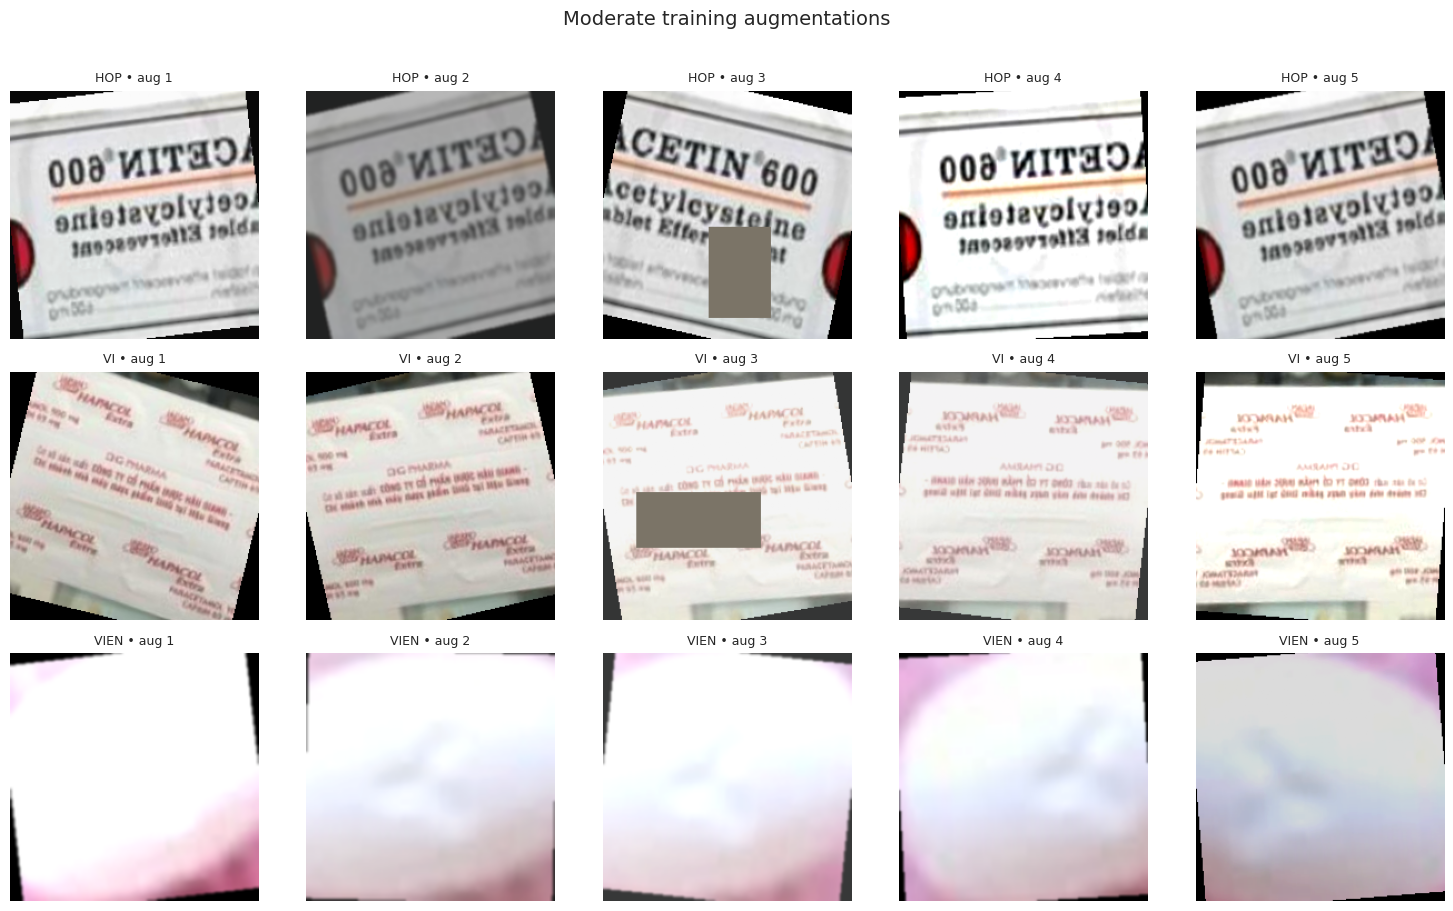

In [11]:
def denormalize_image(tensor: torch.Tensor) -> np.ndarray:
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    image = (tensor.cpu() * std + mean).clamp(0, 1)
    return image.permute(1, 2, 0).numpy()


def show_augmented_samples(variants: int = 5) -> None:
    set_global_seed(cfg.SEED)
    fig, axes = plt.subplots(len(cfg.CLASS_NAMES), variants, figsize=(3 * variants, 3 * len(cfg.CLASS_NAMES)), squeeze=False)
    for row_index, class_name in enumerate(cfg.CLASS_NAMES):
        sample = split_df[(split_df["split"] == "train") & (split_df["class_name"] == class_name)].iloc[0]
        with Image.open(PROJECT_ROOT / sample["relative_path"]) as image:
            image = image.convert("RGB")
            for column_index in range(variants):
                augmented = train_transform(image.copy())
                axes[row_index, column_index].imshow(denormalize_image(augmented))
                axes[row_index, column_index].axis("off")
                axes[row_index, column_index].set_title(f"{class_name} • aug {column_index + 1}", fontsize=9)
    fig.suptitle("Moderate training augmentations", y=1.01, fontsize=14)
    fig.tight_layout()
    fig.savefig(FIGURE_ROOT / "augmented_samples.png", dpi=160, bbox_inches="tight")
    plt.show()

show_augmented_samples()

## 8. Handling Class Imbalance

The default is **class-weighted cross-entropy**. It preserves natural minibatch diversity while increasing the loss contribution of minority classes. This is usually a stable first choice for transfer learning. The notebook also supports a `WeightedRandomSampler` or mild minority-only augmentation, but intentionally applies only one strategy at a time: simultaneously weighting the loss, oversampling, and over-augmenting can over-correct the imbalance and overfit minority examples.

In [12]:
ALLOWED_IMBALANCE_STRATEGIES = {"weighted_loss", "weighted_sampler", "minority_augmentation", "none"}
if cfg.IMBALANCE_STRATEGY not in ALLOWED_IMBALANCE_STRATEGIES:
    raise ValueError(f"IMBALANCE_STRATEGY must be one of {sorted(ALLOWED_IMBALANCE_STRATEGIES)}")

train_frame = split_df[split_df["split"] == "train"].copy().reset_index(drop=True)
val_frame = split_df[split_df["split"] == "val"].copy().reset_index(drop=True)
test_frame = split_df[split_df["split"] == "test"].copy().reset_index(drop=True)

train_counts = train_frame["label"].value_counts().reindex(range(len(cfg.CLASS_NAMES)), fill_value=0).sort_index()
class_weights_np = len(train_frame) / (len(cfg.CLASS_NAMES) * train_counts.to_numpy(dtype=np.float64))
CLASS_WEIGHTS = torch.tensor(class_weights_np, dtype=torch.float32)
max_count = train_counts.max()
minority_class_names = [cfg.CLASS_NAMES[index] for index, count in train_counts.items() if count < max_count]

imbalance_summary = pd.DataFrame({
    "class": cfg.CLASS_NAMES,
    "train_count": train_counts.values,
    "loss_weight": class_weights_np,
})
display(imbalance_summary)
print(f"Selected strategy: {cfg.IMBALANCE_STRATEGY}")
print(f"Minority classes: {minority_class_names}")


def dataloader_common_kwargs() -> Dict[str, Any]:
    return {
        "num_workers": cfg.NUM_WORKERS,
        "pin_memory": bool(cfg.PIN_MEMORY and torch.cuda.is_available()),
        "persistent_workers": bool(cfg.PERSISTENT_WORKERS and cfg.NUM_WORKERS > 0),
        "worker_init_fn": seed_worker,
    }


def build_dataloaders(batch_size: int, seed: int) -> Dict[str, DataLoader]:
    """Build only train/validation loaders; the test manifest is not accessed here."""
    extra_classes = minority_class_names if cfg.IMBALANCE_STRATEGY == "minority_augmentation" else []
    datasets = {
        "train": ManifestDataset(train_frame, train_transform, training=True, minority_classes=extra_classes),
        "val": ManifestDataset(val_frame, eval_transform, training=False),
    }

    common = dataloader_common_kwargs()
    train_generator = seeded_generator(seed)
    if cfg.IMBALANCE_STRATEGY == "weighted_sampler":
        sample_weights = CLASS_WEIGHTS[torch.tensor(train_frame["label"].to_numpy())].double()
        sampler = WeightedRandomSampler(
            weights=sample_weights,
            num_samples=len(sample_weights),
            replacement=True,
            generator=train_generator,
        )
        train_loader = DataLoader(
            datasets["train"], batch_size=batch_size, sampler=sampler, shuffle=False,
            generator=train_generator, **common
        )
    else:
        train_loader = DataLoader(
            datasets["train"], batch_size=batch_size, shuffle=True,
            generator=train_generator, **common
        )

    # A separate generator avoids coupling validation-worker seeds to training shuffles.
    val_loader = DataLoader(
        datasets["val"], batch_size=batch_size, shuffle=False,
        generator=seeded_generator(seed + 1), **common
    )
    return {"train": train_loader, "val": val_loader}


def build_test_dataloader(batch_size: int, seed: int) -> DataLoader:
    """Construct the untouched test loader only in the final-evaluation section."""
    dataset = ManifestDataset(test_frame, eval_transform, training=False)
    return DataLoader(
        dataset, batch_size=batch_size, shuffle=False,
        generator=seeded_generator(seed + 2), **dataloader_common_kwargs()
    )


def build_criterion(device: torch.device) -> nn.Module:
    weight = CLASS_WEIGHTS.to(device) if cfg.IMBALANCE_STRATEGY == "weighted_loss" else None
    return nn.CrossEntropyLoss(weight=weight, label_smoothing=cfg.LABEL_SMOOTHING)

,class,train_count,loss_weight
0,HOP,497,1.257545
1,VI,492,1.270325
2,VIEN,886,0.705418


Selected strategy: weighted_loss
Minority classes: ['HOP', 'VI']


## 9. Visualization Summary

At this point, dataset figures have been saved under `results/figures/`. The next sections define a single reusable modeling and training framework; no architecture-specific training loops are used.

In [13]:
print("Saved data figures:")
for path in sorted(FIGURE_ROOT.glob("*.png")):
    print(" -", path.name)

Saved data figures:
 - augmented_samples.png
 - class_distribution_after_split.png
 - class_distribution_before_split.png
 - confusion_matrix_20261008T092941_629513Z_seed42_14077859__best__4b00f70183ef.png
 - confusion_matrix_20261008T092941_629513Z_seed42_14077859__greedy_soup__4b00f70183ef.png
 - confusion_matrix_20261008T092941_629513Z_seed42_14077859__uniform_soup__4b00f70183ef.png
 - confusion_matrix_20261008T093331_338312Z_seed42_3d040e1c__best__4b00f70183ef.png
 - confusion_matrix_20261008T093331_338312Z_seed42_3d040e1c__greedy_soup__4b00f70183ef.png
 - confusion_matrix_20261008T093331_338312Z_seed42_3d040e1c__uniform_soup__4b00f70183ef.png
 - confusion_matrix_20261008T093731_277024Z_seed42_3009e159__best__4b00f70183ef.png
 - confusion_matrix_20261008T093731_277024Z_seed42_3009e159__greedy_soup__4b00f70183ef.png
 - confusion_matrix_20261008T093731_277024Z_seed42_3009e159__uniform_soup__4b00f70183ef.png
 - confusion_matrix_20261008T094412_454281Z_seed42_01f5a9dd__best__4b00f70183

## 10. Model Definition

All five models use torchvision ImageNet weights. Only the architecture-specific final classifier is replaced. The optimizer receives separate parameter groups for backbone and head learning rates. Backbone freezing and scheduled unfreezing are supported.

In [14]:
MODEL_SPECS: Dict[str, Dict[str, Any]] = {
    "ConvNeXt": {
        "constructor": models.convnext_tiny,
        "weights": models.ConvNeXt_Tiny_Weights.DEFAULT,
        "model_id": "convnext_tiny",
    },
    "DenseNet": {
        "constructor": models.densenet121,
        "weights": models.DenseNet121_Weights.DEFAULT,
        "model_id": "densenet121",
    },
    "ResNet": {
        "constructor": models.resnet50,
        "weights": models.ResNet50_Weights.DEFAULT,
        "model_id": "resnet50",
    },
    "MobileNet": {
        "constructor": models.mobilenet_v3_large,
        "weights": models.MobileNet_V3_Large_Weights.DEFAULT,
        "model_id": "mobilenet_v3_large",
    },
    "SwinT": {
        "constructor": models.swin_t,
        "weights": models.Swin_T_Weights.DEFAULT,
        "model_id": "swin_t",
    },
}


def get_head_module(model: nn.Module, model_name: str) -> nn.Module:
    if model_name == "ConvNeXt":
        return model.classifier
    if model_name == "DenseNet":
        return model.classifier
    if model_name == "ResNet":
        return model.fc
    if model_name == "MobileNet":
        return model.classifier
    if model_name == "SwinT":
        return model.head
    raise KeyError(f"Unknown model name: {model_name}")


def replace_classification_head(model: nn.Module, model_name: str, num_classes: int) -> None:
    if model_name == "ConvNeXt":
        in_features = model.classifier[2].in_features
        model.classifier[2] = nn.Linear(in_features, num_classes)
    elif model_name == "DenseNet":
        model.classifier = nn.Linear(model.classifier.in_features, num_classes)
    elif model_name == "ResNet":
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    elif model_name == "MobileNet":
        in_features = model.classifier[-1].in_features
        model.classifier[-1] = nn.Linear(in_features, num_classes)
    elif model_name == "SwinT":
        model.head = nn.Linear(model.head.in_features, num_classes)
    else:
        raise KeyError(f"Unknown model name: {model_name}")


def create_model(model_name: str, pretrained: bool = True) -> nn.Module:
    if model_name not in MODEL_SPECS:
        raise KeyError(f"Unknown model '{model_name}'. Choose from {list(MODEL_SPECS)}")
    spec = MODEL_SPECS[model_name]
    weights = spec["weights"] if pretrained else None
    try:
        model = spec["constructor"](weights=weights)
    except Exception as exc:
        if pretrained:
            raise RuntimeError(
                f"Could not load pretrained weights for {model_name}. Check internet/cache availability."
            ) from exc
        raise
    replace_classification_head(model, model_name, len(cfg.CLASS_NAMES))
    return model


def set_backbone_trainable(model: nn.Module, model_name: str, trainable: bool) -> None:
    for parameter in model.parameters():
        parameter.requires_grad = trainable
    # The new head always remains trainable.
    for parameter in get_head_module(model, model_name).parameters():
        parameter.requires_grad = True


def set_training_mode(model: nn.Module, model_name: str, backbone_frozen: bool) -> None:
    if backbone_frozen:
        # Keep frozen BatchNorm/dropout layers fixed while allowing head dropout (if present).
        model.eval()
        get_head_module(model, model_name).train()
    else:
        model.train()


def count_parameters(model: nn.Module) -> Tuple[int, int]:
    total = sum(parameter.numel() for parameter in model.parameters())
    trainable = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
    return total, trainable


def parameter_state_size_mb(model: nn.Module) -> float:
    total_bytes = sum(tensor.numel() * tensor.element_size() for tensor in model.state_dict().values())
    return total_bytes / 1024**2


def build_optimizer(model: nn.Module, model_name: str) -> torch.optim.Optimizer:
    head_ids = {id(parameter) for parameter in get_head_module(model, model_name).parameters()}
    backbone_parameters = [parameter for parameter in model.parameters() if id(parameter) not in head_ids]
    head_parameters = [parameter for parameter in model.parameters() if id(parameter) in head_ids]
    return torch.optim.AdamW([
        {"params": backbone_parameters, "lr": cfg.BACKBONE_LEARNING_RATE, "group_name": "backbone"},
        {"params": head_parameters, "lr": cfg.LEARNING_RATE, "group_name": "head"},
    ], weight_decay=cfg.WEIGHT_DECAY)

## 11. Training Framework

The loop supports AMP, gradient accumulation, clipping, early stopping, a validation-macro-F1 scheduler, and frozen-to-unfrozen fine-tuning. Macro F1 drives checkpoint ranking because the data are imbalanced. Epoch loss, accuracy, macro F1, learning rates, and timings are retained.

In [15]:
def make_grad_scaler(enabled: bool):
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=enabled)



def autocast_context(enabled: bool):
    if enabled:
        return torch.autocast(device_type="cuda", dtype=torch.float16)
    return nullcontext()


def synchronize_if_cuda() -> None:
    if torch.cuda.is_available():
        torch.cuda.synchronize()


def train_one_epoch(
    model: nn.Module,
    model_name: str,
    loader: DataLoader,
    criterion: nn.Module,
    optimizer: torch.optim.Optimizer,
    scaler: Any,
    backbone_frozen: bool,
) -> Dict[str, float]:
    set_training_mode(model, model_name, backbone_frozen)
    optimizer.zero_grad(set_to_none=True)
    total_loss = 0.0
    total_examples = 0
    targets_all: List[int] = []
    predictions_all: List[int] = []
    amp_enabled = bool(cfg.USE_AMP and DEVICE.type == "cuda")

    for step, (inputs, targets, _) in enumerate(loader):
        inputs = inputs.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        with autocast_context(amp_enabled):
            logits = model(inputs)
            raw_loss = criterion(logits, targets)
            loss = raw_loss / cfg.GRADIENT_ACCUMULATION_STEPS
        scaler.scale(loss).backward()

        should_step = ((step + 1) % cfg.GRADIENT_ACCUMULATION_STEPS == 0) or (step + 1 == len(loader))
        if should_step:
            if cfg.MAX_GRAD_NORM is not None:
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), cfg.MAX_GRAD_NORM)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

        batch_size = targets.size(0)
        total_loss += raw_loss.detach().item() * batch_size
        total_examples += batch_size
        targets_all.extend(targets.detach().cpu().tolist())
        predictions_all.extend(logits.detach().argmax(dim=1).cpu().tolist())

    accuracy = accuracy_score(targets_all, predictions_all)
    macro_f1 = precision_recall_fscore_support(
        targets_all, predictions_all, labels=list(range(len(cfg.CLASS_NAMES))),
        average="macro", zero_division=0
    )[2]
    return {"loss": total_loss / total_examples, "accuracy": accuracy, "macro_f1": macro_f1}


@torch.inference_mode()
def evaluate_one_epoch(model: nn.Module, loader: DataLoader, criterion: nn.Module) -> Dict[str, float]:
    model.eval()
    total_loss = 0.0
    total_examples = 0
    targets_all: List[int] = []
    predictions_all: List[int] = []
    amp_enabled = bool(cfg.USE_AMP and DEVICE.type == "cuda")

    for inputs, targets, _ in loader:
        inputs = inputs.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        with autocast_context(amp_enabled):
            logits = model(inputs)
            loss = criterion(logits, targets)
        batch_size = targets.size(0)
        total_loss += loss.item() * batch_size
        total_examples += batch_size
        targets_all.extend(targets.cpu().tolist())
        predictions_all.extend(logits.argmax(dim=1).cpu().tolist())

    accuracy = accuracy_score(targets_all, predictions_all)
    macro_f1 = precision_recall_fscore_support(
        targets_all, predictions_all, labels=list(range(len(cfg.CLASS_NAMES))),
        average="macro", zero_division=0
    )[2]
    return {"loss": total_loss / total_examples, "accuracy": accuracy, "macro_f1": macro_f1}

## 12. Checkpoint Management

Every run gets a unique UTC timestamp/UUID directory, so prior experiments are not overwritten. The manager retains the validation-macro-F1 top-K checkpoints plus periodic/final checkpoints. Metadata records architecture, epoch, validation loss/accuracy/F1, path, configuration, and seed. Only same-architecture state dictionaries are later averaged.

In [16]:
class CheckpointManager:
    def __init__(self, model_name: str, run_id: str, run_dir: Path, config: Mapping[str, Any]) -> None:
        self.model_name = model_name
        self.run_id = run_id
        self.run_dir = run_dir
        self.run_dir.mkdir(parents=True, exist_ok=False)
        self.config = dict(config)
        self.records: Dict[int, Dict[str, Any]] = {}
        self.top_epochs: List[int] = []
        self.metadata_path = self.run_dir / "checkpoint_metadata.json"

    @staticmethod
    def _rank(record: Mapping[str, Any]) -> Tuple[float, float]:
        return (float(record["validation_f1"]), -float(record["validation_loss"]))

    def _checkpoint_path(self, epoch: int) -> Path:
        return self.run_dir / f"epoch_{epoch:03d}.pt"

    def _save_payload(
        self,
        path: Path,
        model: nn.Module,
        optimizer: torch.optim.Optimizer,
        scheduler: Any,
        epoch: int,
        metrics: Mapping[str, float],
    ) -> None:
        payload = {
            "model_name": self.model_name,
            "model_id": MODEL_SPECS[self.model_name]["model_id"],
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "validation_loss": float(metrics["loss"]),
            "validation_accuracy": float(metrics["accuracy"]),
            "validation_f1": float(metrics["macro_f1"]),
            "config": self.config,
            "seed": cfg.SEED,
            "split_fingerprint": SPLIT_FINGERPRINT,
        }
        if cfg.SAVE_OPTIMIZER_STATE:
            # Useful for exact resume, but roughly triples AdamW checkpoint size.
            payload["optimizer_state_dict"] = optimizer.state_dict()
            payload["scheduler_state_dict"] = scheduler.state_dict()
        temporary_path = path.with_suffix(".tmp")
        torch.save(payload, temporary_path)
        temporary_path.replace(path)

    def save_epoch(
        self,
        model: nn.Module,
        optimizer: torch.optim.Optimizer,
        scheduler: Any,
        epoch: int,
        metrics: Mapping[str, float],
        is_final: bool,
    ) -> None:
        candidate_record = {
            "model_name": self.model_name,
            "model_id": MODEL_SPECS[self.model_name]["model_id"],
            "epoch": int(epoch),
            "validation_loss": float(metrics["loss"]),
            "validation_accuracy": float(metrics["accuracy"]),
            "validation_f1": float(metrics["macro_f1"]),
            "checkpoint_path": str(self._checkpoint_path(epoch)),
            "training_config": self.config,
            "random_seed": cfg.SEED,
            "split_fingerprint": SPLIT_FINGERPRINT,
            "tags": [],
        }
        current_top_records = [self.records[e] for e in self.top_epochs if e in self.records]
        qualifies_top_k = (
            len(current_top_records) < cfg.TOP_K_CHECKPOINTS or
            self._rank(candidate_record) > min(self._rank(record) for record in current_top_records)
        )
        is_periodic = epoch % cfg.CHECKPOINT_INTERVAL == 0
        should_save = qualifies_top_k or is_periodic or is_final

        if should_save:
            tags = []
            if is_periodic:
                tags.append("periodic")
            if is_final:
                tags.append("final")
            candidate_record["tags"] = tags
            self._save_payload(self._checkpoint_path(epoch), model, optimizer, scheduler, epoch, metrics)
            self.records[epoch] = candidate_record

        if qualifies_top_k:
            if epoch not in self.records:
                self._save_payload(self._checkpoint_path(epoch), model, optimizer, scheduler, epoch, metrics)
                self.records[epoch] = candidate_record
            prospective = list(set(self.top_epochs + [epoch]))
            prospective.sort(key=lambda e: self._rank(self.records[e]), reverse=True)
            self.top_epochs = prospective[:cfg.TOP_K_CHECKPOINTS]

        # Re-tag top-K/best and delete checkpoints that lost top-K status and have no durable tag.
        for record_epoch, record in list(self.records.items()):
            durable_tags = [tag for tag in record["tags"] if tag in {"periodic", "final"}]
            if record_epoch in self.top_epochs:
                durable_tags.append("top_k")
            record["tags"] = sorted(set(durable_tags))
            if not record["tags"]:
                Path(record["checkpoint_path"]).unlink(missing_ok=True)
                del self.records[record_epoch]
        if self.top_epochs:
            best_epoch = self.top_epochs[0]
            self.records[best_epoch]["tags"] = sorted(set(self.records[best_epoch]["tags"] + ["best"]))
        self.write_metadata()

    def write_metadata(self) -> None:
        payload = {
            "model_name": self.model_name,
            "run_id": self.run_id,
            "random_seed": cfg.SEED,
            "split_fingerprint": SPLIT_FINGERPRINT,
            "training_config": self.config,
            "saved_checkpoints": sorted(self.records.values(), key=lambda row: row["epoch"]),
        }
        with self.metadata_path.open("w") as handle:
            json.dump(json_safe(payload), handle, indent=2)

    def best_record(self) -> Dict[str, Any]:
        if not self.top_epochs:
            raise RuntimeError("No top-K checkpoint was saved.")
        return self.records[self.top_epochs[0]]

    def top_k_records(self) -> List[Dict[str, Any]]:
        return [self.records[epoch] for epoch in self.top_epochs]

In [17]:
def make_run_id(model_name: str) -> str:
    timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
    return f"{timestamp}_seed{cfg.SEED}_{uuid.uuid4().hex[:8]}"


def plot_training_history(history: pd.DataFrame, model_name: str, run_id: str) -> Path:
    figure_path = FIGURE_ROOT / f"training_curves_{model_name}_{run_id}.png"
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    axes[0].plot(history["epoch"], history["train_loss"], label="Train")
    axes[0].plot(history["epoch"], history["val_loss"], label="Validation")
    axes[0].set(title="Loss", xlabel="Epoch", ylabel="Cross-entropy")
    axes[1].plot(history["epoch"], history["train_accuracy"], label="Train")
    axes[1].plot(history["epoch"], history["val_accuracy"], label="Validation")
    axes[1].set(title="Accuracy", xlabel="Epoch", ylabel="Accuracy")
    axes[2].plot(history["epoch"], history["train_macro_f1"], label="Train")
    axes[2].plot(history["epoch"], history["val_macro_f1"], label="Validation")
    axes[2].set(title="Macro F1", xlabel="Epoch", ylabel="Macro F1")
    for ax in axes:
        ax.legend()
        ax.grid(alpha=0.3)
    fig.suptitle(f"{model_name} training history")
    fig.tight_layout()
    fig.savefig(figure_path, dpi=160, bbox_inches="tight")
    plt.show()
    return figure_path


def train_experiment(model_name: str) -> Dict[str, Any]:
    set_global_seed(cfg.SEED)
    batch_size = cfg.MODEL_BATCH_SIZES.get(model_name, cfg.BATCH_SIZE)
    loaders = build_dataloaders(batch_size=batch_size, seed=cfg.SEED)

    model = create_model(model_name, pretrained=cfg.PRETRAINED)
    set_backbone_trainable(model, model_name, trainable=not cfg.FREEZE_BACKBONE)
    model = model.to(DEVICE)
    total_parameters, initial_trainable_parameters = count_parameters(model)
    optimizer = build_optimizer(model, model_name)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=cfg.LR_SCHEDULER_FACTOR,
        patience=cfg.LR_SCHEDULER_PATIENCE,
    )
    criterion = build_criterion(DEVICE)
    amp_enabled = bool(cfg.USE_AMP and DEVICE.type == "cuda")
    scaler = make_grad_scaler(amp_enabled)

    run_id = make_run_id(model_name)
    run_dir = CHECKPOINT_ROOT / model_name / run_id
    run_config = {**CONFIG_DICT, "effective_batch_size": batch_size, "model_name": model_name}
    manager = CheckpointManager(model_name, run_id, run_dir, run_config)

    history_rows: List[Dict[str, Any]] = []
    best_val_f1 = -math.inf
    epochs_without_improvement = 0
    backbone_frozen = cfg.FREEZE_BACKBONE
    training_start = time.perf_counter()
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()

    print(f"\nTraining {model_name} | batch={batch_size} | AMP={amp_enabled} | run={run_id}")
    for epoch in range(1, cfg.NUM_EPOCHS + 1):
        if backbone_frozen and cfg.UNFREEZE_EPOCH is not None and epoch >= cfg.UNFREEZE_EPOCH:
            set_backbone_trainable(model, model_name, trainable=True)
            backbone_frozen = False
            print(f"Epoch {epoch}: backbone unfrozen; optimizer parameter groups now receive gradients.")

        synchronize_if_cuda()
        epoch_start = time.perf_counter()
        learning_rates = {group.get("group_name", str(i)): group["lr"] for i, group in enumerate(optimizer.param_groups)}
        train_metrics = train_one_epoch(
            model, model_name, loaders["train"], criterion, optimizer, scaler, backbone_frozen
        )
        val_metrics = evaluate_one_epoch(model, loaders["val"], criterion)
        scheduler.step(val_metrics["macro_f1"])
        synchronize_if_cuda()
        epoch_time = time.perf_counter() - epoch_start

        improved = val_metrics["macro_f1"] > best_val_f1 + cfg.EARLY_STOPPING_MIN_DELTA
        if improved:
            best_val_f1 = val_metrics["macro_f1"]
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
        should_stop = epochs_without_improvement >= cfg.EARLY_STOPPING_PATIENCE
        is_final = should_stop or epoch == cfg.NUM_EPOCHS

        manager.save_epoch(model, optimizer, scheduler, epoch, val_metrics, is_final=is_final)
        row = {
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "val_loss": val_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "val_accuracy": val_metrics["accuracy"],
            "train_macro_f1": train_metrics["macro_f1"],
            "val_macro_f1": val_metrics["macro_f1"],
            "backbone_lr": learning_rates.get("backbone", np.nan),
            "head_lr": learning_rates.get("head", np.nan),
            "epoch_time_seconds": epoch_time,
            "backbone_frozen": backbone_frozen,
        }
        history_rows.append(row)
        print(
            f"Epoch {epoch:02d}/{cfg.NUM_EPOCHS} | "
            f"train loss {row['train_loss']:.4f}, acc {row['train_accuracy']:.4f}, F1 {row['train_macro_f1']:.4f} | "
            f"val loss {row['val_loss']:.4f}, acc {row['val_accuracy']:.4f}, F1 {row['val_macro_f1']:.4f} | "
            f"{epoch_time:.1f}s"
        )
        if should_stop:
            print(f"Early stopping after {epoch} epochs (patience={cfg.EARLY_STOPPING_PATIENCE}).")
            break

    synchronize_if_cuda()
    total_training_time = time.perf_counter() - training_start
    training_peak_memory_mb = (
        torch.cuda.max_memory_allocated() / 1024**2 if torch.cuda.is_available() else np.nan
    )
    history = pd.DataFrame(history_rows)
    history_path = run_dir / "training_history.csv"
    history.to_csv(history_path, index=False)
    curve_path = plot_training_history(history, model_name, run_id)

    best = manager.best_record()
    summary = {
        "model_name": model_name,
        "model_id": MODEL_SPECS[model_name]["model_id"],
        "run_id": run_id,
        "run_dir": str(run_dir),
        "best_checkpoint_path": best["checkpoint_path"],
        "best_epoch": best["epoch"],
        "best_validation_f1": best["validation_f1"],
        "best_validation_accuracy": best["validation_accuracy"],
        "best_validation_loss": best["validation_loss"],
        "checkpoint_metadata_path": str(manager.metadata_path),
        "history_path": str(history_path),
        "curve_path": str(curve_path),
        "total_training_time_seconds": total_training_time,
        "average_epoch_time_seconds": float(history["epoch_time_seconds"].mean()),
        "epochs_completed": int(len(history)),
        "num_parameters": int(total_parameters),
        "initial_trainable_parameters": int(initial_trainable_parameters),
        "training_peak_gpu_memory_mb": float(training_peak_memory_mb),
        "effective_batch_size": batch_size,
        "split_fingerprint": SPLIT_FINGERPRINT,
        "config": run_config,
    }
    with (run_dir / "run_summary.json").open("w") as handle:
        json.dump(json_safe(summary), handle, indent=2)
    print(f"Best {model_name} epoch: {best['epoch']} | validation macro F1={best['validation_f1']:.4f}")

    del model, optimizer, scheduler, scaler, loaders
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return summary

## 13. Training All Models

This cell runs all configured architectures sequentially and clears GPU memory between runs. Set `RUN_TRAINING=False` to reuse the `results/metrics/current_runs.json` pointer from a completed execution. A full five-model run can take substantial time; reduce epochs or model list for a smoke test, but keep the split and seed unchanged for comparable experiments.

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 152MB/s]



Training ConvNeXt | batch=24 | AMP=True | run=20261008T151526_044402Z_seed43_29021323
Epoch 01/25 | train loss 0.8942, acc 0.6864, F1 0.6852 | val loss 0.7278, acc 0.8905, F1 0.8888 | 43.3s
Epoch 02/25 | train loss 0.6204, acc 0.9429, F1 0.9364 | val loss 0.5314, acc 0.9602, F1 0.9587 | 37.6s
Epoch 3: backbone unfrozen; optimizer parameter groups now receive gradients.
Epoch 03/25 | train loss 0.4170, acc 0.9781, F1 0.9772 | val loss 0.3855, acc 0.9851, F1 0.9836 | 49.9s
Epoch 04/25 | train loss 0.3682, acc 0.9813, F1 0.9801 | val loss 0.3705, acc 0.9925, F1 0.9923 | 40.2s
Epoch 05/25 | train loss 0.3490, acc 0.9893, F1 0.9890 | val loss 0.3632, acc 0.9925, F1 0.9927 | 42.2s
Epoch 06/25 | train loss 0.3424, acc 0.9931, F1 0.9927 | val loss 0.3588, acc 0.9950, F1 0.9951 | 42.3s
Epoch 07/25 | train loss 0.3371, acc 0.9952, F1 0.9950 | val loss 0.3547, acc 0.9925, F1 0.9927 | 42.4s
Epoch 08/25 | train loss 0.3306, acc 0.9952, F1 0.9950 | val loss 0.3507, acc 0.9925, F1 0.9927 | 41.5s
Epo

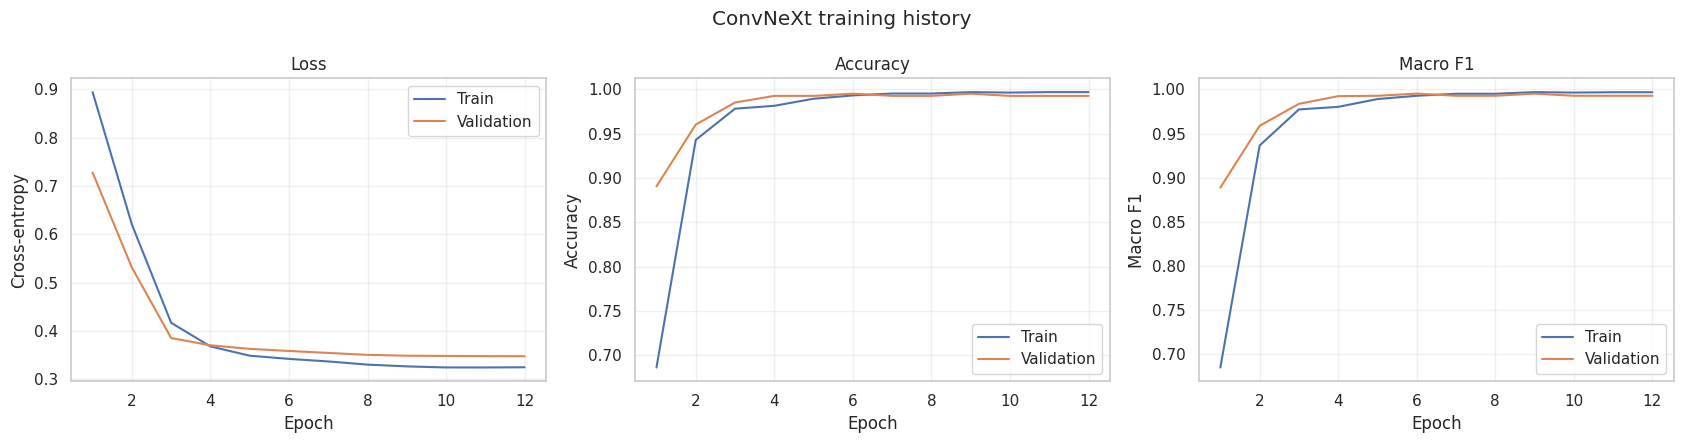

Best ConvNeXt epoch: 9 | validation macro F1=0.9951
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 162MB/s]


Training DenseNet | batch=24 | AMP=True | run=20261008T152359_734636Z_seed43_6e6cf325


Epoch 01/25 | train loss 0.9767, acc 0.6261, F1 0.5946 | val loss 0.7946, acc 0.8333, F1 0.8228 | 42.2s
Epoch 02/25 | train loss 0.7303, acc 0.9056, F1 0.8904 | val loss 0.6179, acc 0.9353, F1 0.9319 | 39.1s
Epoch 3: backbone unfrozen; optimizer parameter groups now receive gradients.
Epoch 03/25 | train loss 0.6003, acc 0.9093, F1 0.8992 | val loss 0.4732, acc 0.9577, F1 0.9577 | 45.0s
Epoch 04/25 | train loss 0.4559, acc 0.9493, F1 0.9445 | val loss 0.4119, acc 0.9701, F1 0.9696 | 43.4s
Epoch 05/25 | train loss 0.4066, acc 0.9632, F1 0.9604 | val loss 0.3964, acc 0.9751, F1 0.9744 | 43.4s
Epoch 06/25 | train loss 0.4000, acc 0.9712, F1 0.9698 | val loss 0.3883, acc 0.9851, F1 0.9845 | 43.7s
Epoch 07/25 | train loss 0.3890, acc 0.9739, F1 0.9727 | val loss 0.3860, acc 0.9900, F1 0.9899 | 45.4s
Epoch 08/25 | train loss 0.3822, acc 0.9765, F1 0.9750 | val loss 0.3799, acc 0.9876, F1 0.9875 | 44.6s
Epoch 09/25 | train loss 0.3667, acc 0.9877, F1 0.9870 | val loss 0.3733, acc 0.9900, F1 0

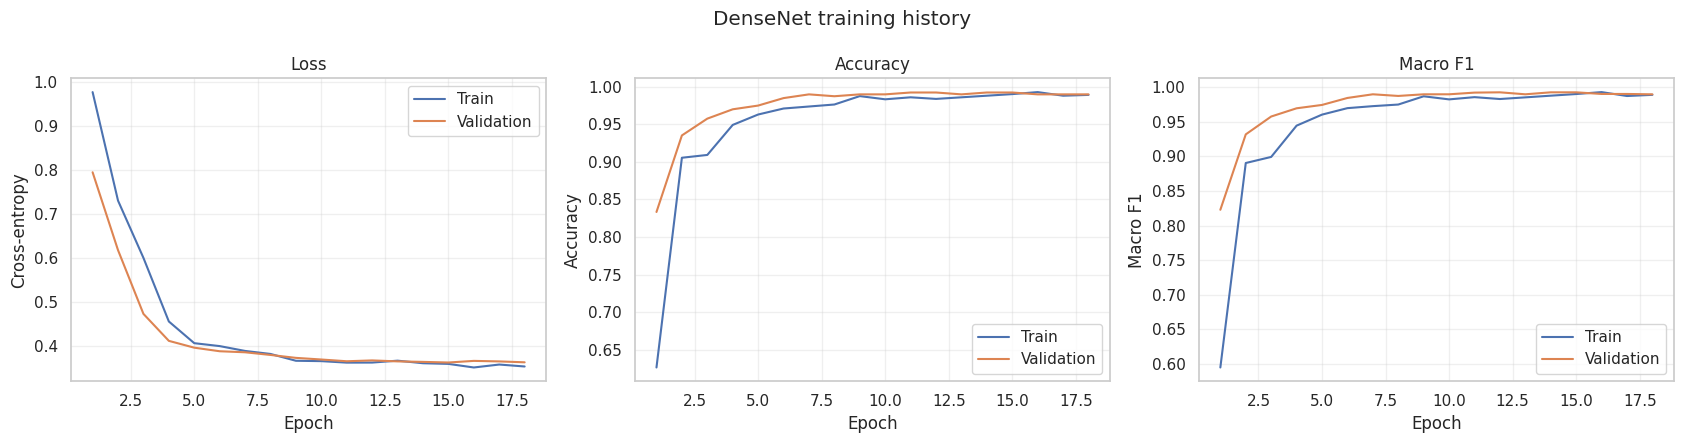

Best DenseNet epoch: 15 | validation macro F1=0.9927
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 171MB/s]



Training ResNet | batch=32 | AMP=True | run=20261008T153712_898887Z_seed43_f183e87a
Epoch 01/25 | train loss 1.0072, acc 0.6512, F1 0.5941 | val loss 0.8646, acc 0.8706, F1 0.8502 | 39.7s
Epoch 02/25 | train loss 0.7760, acc 0.9093, F1 0.8889 | val loss 0.6832, acc 0.9552, F1 0.9514 | 38.7s
Epoch 3: backbone unfrozen; optimizer parameter groups now receive gradients.
Epoch 03/25 | train loss 0.7004, acc 0.9045, F1 0.8954 | val loss 0.5377, acc 0.9527, F1 0.9497 | 40.9s
Epoch 04/25 | train loss 0.4845, acc 0.9531, F1 0.9480 | val loss 0.4388, acc 0.9527, F1 0.9500 | 41.6s
Epoch 05/25 | train loss 0.4125, acc 0.9664, F1 0.9633 | val loss 0.4182, acc 0.9627, F1 0.9602 | 39.1s
Epoch 06/25 | train loss 0.4032, acc 0.9691, F1 0.9675 | val loss 0.4058, acc 0.9701, F1 0.9691 | 40.1s
Epoch 07/25 | train loss 0.4036, acc 0.9675, F1 0.9647 | val loss 0.3962, acc 0.9801, F1 0.9801 | 41.1s
Epoch 08/25 | train loss 0.3892, acc 0.9760, F1 0.9744 | val loss 0.3915, acc 0.9826, F1 0.9826 | 39.4s
Epoch

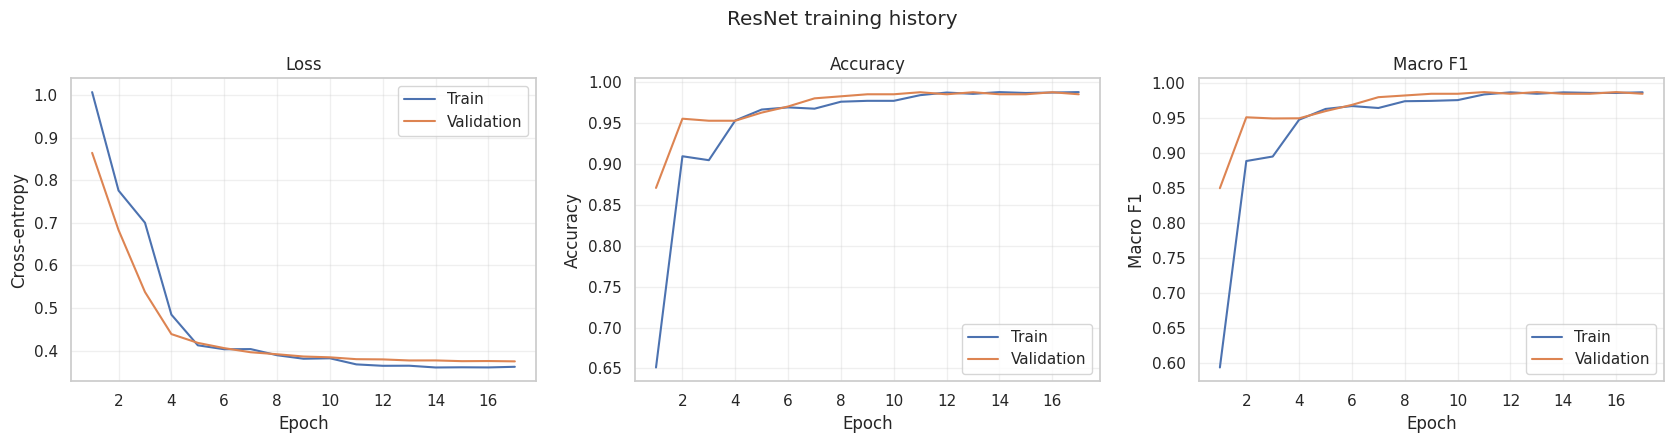

Best ResNet epoch: 16 | validation macro F1=0.9874
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 163MB/s]



Training MobileNet | batch=48 | AMP=True | run=20261008T154844_818721Z_seed43_0330b902
Epoch 01/25 | train loss 0.6925, acc 0.8795, F1 0.8703 | val loss 0.4777, acc 0.9726, F1 0.9720 | 40.9s
Epoch 02/25 | train loss 0.4309, acc 0.9659, F1 0.9627 | val loss 0.4170, acc 0.9726, F1 0.9724 | 37.2s
Epoch 3: backbone unfrozen; optimizer parameter groups now receive gradients.
Epoch 03/25 | train loss 0.4972, acc 0.9397, F1 0.9342 | val loss 0.4160, acc 0.9776, F1 0.9777 | 42.3s
Epoch 04/25 | train loss 0.4238, acc 0.9627, F1 0.9593 | val loss 0.4088, acc 0.9851, F1 0.9850 | 40.3s
Epoch 05/25 | train loss 0.3979, acc 0.9717, F1 0.9700 | val loss 0.3999, acc 0.9826, F1 0.9826 | 38.7s
Epoch 06/25 | train loss 0.3843, acc 0.9792, F1 0.9788 | val loss 0.3942, acc 0.9826, F1 0.9830 | 40.1s
Epoch 07/25 | train loss 0.3799, acc 0.9803, F1 0.9794 | val loss 0.3907, acc 0.9826, F1 0.9830 | 38.4s
Epoch 08/25 | train loss 0.3770, acc 0.9792, F1 0.9782 | val loss 0.3905, acc 0.9801, F1 0.9806 | 39.2s
Ep

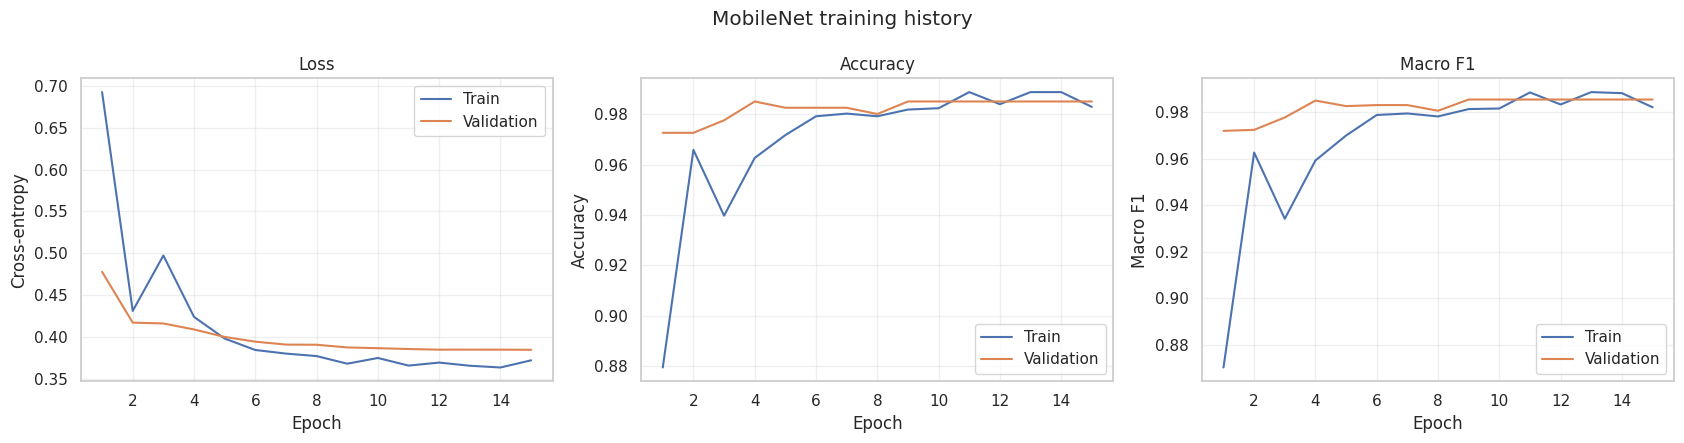

Best MobileNet epoch: 15 | validation macro F1=0.9854
Downloading: "https://download.pytorch.org/models/swin_t-704ceda3.pth" to /root/.cache/torch/hub/checkpoints/swin_t-704ceda3.pth


100%|██████████| 108M/108M [00:00<00:00, 123MB/s]



Training SwinT | batch=16 | AMP=True | run=20261008T155841_087592Z_seed43_3861d59f
Epoch 01/25 | train loss 0.8895, acc 0.6448, F1 0.6447 | val loss 0.6852, acc 0.9080, F1 0.9066 | 40.6s
Epoch 02/25 | train loss 0.5391, acc 0.9536, F1 0.9504 | val loss 0.4774, acc 0.9652, F1 0.9636 | 41.6s
Epoch 3: backbone unfrozen; optimizer parameter groups now receive gradients.
Epoch 03/25 | train loss 0.3979, acc 0.9723, F1 0.9704 | val loss 0.3694, acc 0.9876, F1 0.9869 | 47.0s
Epoch 04/25 | train loss 0.3622, acc 0.9845, F1 0.9836 | val loss 0.3573, acc 0.9925, F1 0.9927 | 46.3s
Epoch 05/25 | train loss 0.3488, acc 0.9904, F1 0.9899 | val loss 0.3535, acc 0.9925, F1 0.9927 | 47.1s
Epoch 06/25 | train loss 0.3394, acc 0.9931, F1 0.9929 | val loss 0.3501, acc 0.9925, F1 0.9922 | 46.7s
Epoch 07/25 | train loss 0.3342, acc 0.9931, F1 0.9930 | val loss 0.3486, acc 0.9925, F1 0.9927 | 47.6s
Epoch 08/25 | train loss 0.3319, acc 0.9952, F1 0.9951 | val loss 0.3446, acc 0.9925, F1 0.9927 | 48.8s
Epoch 

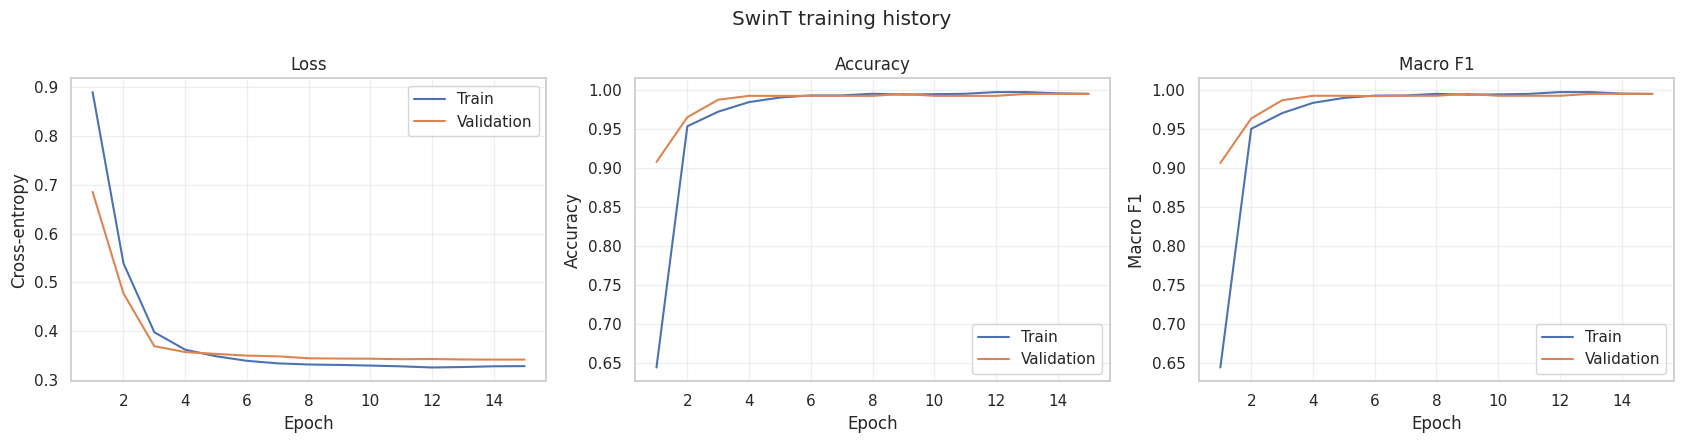

Best SwinT epoch: 14 | validation macro F1=0.9951


,Model,Run ID,Best Epoch,Best Validation Macro F1,Training Time (s),Peak Training GPU MB
0,ConvNeXt,20261008T151526_044402Z_seed43_29021323,9,0.995127,511.298555,1894.540039
1,DenseNet,20261008T152359_734636Z_seed43_6e6cf325,15,0.992701,790.659583,1713.331543
2,ResNet,20261008T153712_898887Z_seed43_f183e87a,16,0.987377,689.436683,1772.001953
3,MobileNet,20261008T154844_818721Z_seed43_0330b902,15,0.985445,592.802380,1178.135742
4,SwinT,20261008T155841_087592Z_seed43_3861d59f,14,0.995127,707.979795,1534.122070


In [18]:
def load_current_runs() -> Dict[str, Dict[str, Any]]:
    pointer = METRICS_ROOT / "current_runs.json"
    if not pointer.exists():
        raise FileNotFoundError("No current_runs.json exists. Set RUN_TRAINING=True for the first run.")
    with pointer.open() as handle:
        runs = json.load(handle)
    for name, summary in runs.items():
        if summary.get("split_fingerprint") != SPLIT_FINGERPRINT:
            raise RuntimeError(f"Saved run {name} used a different data split.")
        if not Path(summary["best_checkpoint_path"]).exists():
            raise FileNotFoundError(summary["best_checkpoint_path"])
    return runs


if cfg.RUN_TRAINING:
    pointer_path = METRICS_ROOT / "current_runs.json"
    IGNORED_KEYS = {"MODELS_TO_TRAIN", "MODEL_NAME", "RUN_TRAINING", "RUN_MODEL_SOUP"}

    def reusable(summary: Mapping[str, Any]) -> bool:
        saved_cfg = summary.get("config", {})
        same_cfg = all(saved_cfg.get(k) == v for k, v in CONFIG_DICT.items() if k not in IGNORED_KEYS)
        return (
            summary.get("split_fingerprint") == SPLIT_FINGERPRINT
            and same_cfg
            and Path(summary["best_checkpoint_path"]).exists()
        )

    trained_runs: Dict[str, Dict[str, Any]] = {}
    if pointer_path.exists():
        with pointer_path.open() as handle:
            trained_runs = {name: s for name, s in json.load(handle).items() if reusable(s)}

    for selected_model_name in cfg.MODELS_TO_TRAIN:
        if selected_model_name in trained_runs:
            print(f"Skipping {selected_model_name}: already trained (run {trained_runs[selected_model_name]['run_id']}).")
            continue
        trained_runs[selected_model_name] = train_experiment(selected_model_name)
        with pointer_path.open("w") as handle:   # saved after EACH model
            json.dump(json_safe(trained_runs), handle, indent=2)
else:
    trained_runs = load_current_runs()

run_overview = pd.DataFrame([
    {
        "Model": summary["model_name"],
        "Run ID": summary["run_id"],
        "Best Epoch": summary["best_epoch"],
        "Best Validation Macro F1": summary["best_validation_f1"],
        "Training Time (s)": summary["total_training_time_seconds"],
        "Peak Training GPU MB": summary["training_peak_gpu_memory_mb"],
    }
    for summary in trained_runs.values()
])
display(run_overview)

## 14. Model Soup

A model soup averages parameters from multiple fine-tuned checkpoints of the **same architecture**:

- **Uniform soup:** equally averages every validation-selected top-K checkpoint.
- **Greedy soup:** starts with the best validation checkpoint, then adds a candidate only when the running average does not reduce validation macro F1 (subject to `GREEDY_SOUP_MIN_DELTA`).

The test loader is never accessed here. Floating-point tensors are averaged in CPU float32; integer buffers (such as BatchNorm counters) are retained from the first ingredient. Averaging checkpoints in a shared low-loss basin can improve generalization without increasing inference cost.

In [19]:
def load_checkpoint_payload(path: Path) -> Dict[str, Any]:
    try:
        return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:  # older PyTorch
        return torch.load(path, map_location="cpu")


def extract_state_dict(path: Path, expected_model_name: Optional[str] = None) -> Dict[str, torch.Tensor]:
    payload = load_checkpoint_payload(path)
    if expected_model_name is not None and payload.get("model_name") != expected_model_name:
        raise ValueError(
            f"Architecture mismatch: expected {expected_model_name}, found {payload.get('model_name')} in {path}"
        )
    state = payload.get("model_state_dict")
    if state is None:
        raise KeyError(f"No model_state_dict in {path}")
    return {key: value.detach().cpu() for key, value in state.items()}


def average_state_dicts(checkpoint_paths: Sequence[Path], model_name: str) -> Dict[str, torch.Tensor]:
    if not checkpoint_paths:
        raise ValueError("At least one checkpoint is required for a soup.")
    average = extract_state_dict(checkpoint_paths[0], model_name)
    average = {
        key: (value.float().clone() if torch.is_floating_point(value) else value.clone())
        for key, value in average.items()
    }
    for count, path in enumerate(checkpoint_paths[1:], start=2):
        new_state = extract_state_dict(path, model_name)
        if average.keys() != new_state.keys():
            raise ValueError(f"State-dict keys differ for {path}")
        for key in average:
            if average[key].shape != new_state[key].shape:
                raise ValueError(f"Shape mismatch for {key} in {path}")
            if torch.is_floating_point(new_state[key]):
                average[key].mul_((count - 1) / count).add_(new_state[key].float(), alpha=1 / count)
            # Non-floating buffers remain from the first checkpoint.
    return average


def add_state_to_running_average(
    running: Mapping[str, torch.Tensor],
    new_state: Mapping[str, torch.Tensor],
    current_count: int,
) -> Dict[str, torch.Tensor]:
    proposal: Dict[str, torch.Tensor] = {}
    for key, current in running.items():
        candidate = new_state[key]
        if current.shape != candidate.shape:
            raise ValueError(f"Shape mismatch for key {key}")
        if torch.is_floating_point(candidate):
            proposal[key] = current.float() * (current_count / (current_count + 1)) + candidate.float() / (current_count + 1)
        else:
            proposal[key] = current.clone()
    return proposal


def validation_metrics_for_state(
    model: nn.Module,
    state: Mapping[str, torch.Tensor],
    val_loader: DataLoader,
    criterion: nn.Module,
) -> Dict[str, float]:
    model.load_state_dict(state, strict=True)
    return evaluate_one_epoch(model, val_loader, criterion)


def save_soup_checkpoint(
    path: Path,
    model_name: str,
    state: Mapping[str, torch.Tensor],
    soup_type: str,
    sources: Sequence[str],
    validation_metrics: Mapping[str, float],
    run_id: str,
) -> None:
    payload = {
        "model_name": model_name,
        "model_id": MODEL_SPECS[model_name]["model_id"],
        "model_state_dict": dict(state),
        "soup_type": soup_type,
        "source_checkpoints": list(sources),
        "number_of_checkpoints": len(sources),
        "validation_loss": float(validation_metrics["loss"]),
        "validation_accuracy": float(validation_metrics["accuracy"]),
        "validation_f1": float(validation_metrics["macro_f1"]),
        "run_id": run_id,
        "seed": cfg.SEED,
        "split_fingerprint": SPLIT_FINGERPRINT,
        "config": CONFIG_DICT,
    }
    temporary = path.with_suffix(".tmp")
    torch.save(payload, temporary)
    temporary.replace(path)


def construct_soups(run_summary: Mapping[str, Any]) -> List[Dict[str, Any]]:
    model_name = run_summary["model_name"]
    with Path(run_summary["checkpoint_metadata_path"]).open() as handle:
        metadata = json.load(handle)
    candidates = [
        record for record in metadata["saved_checkpoints"] if "top_k" in record.get("tags", [])
    ]
    candidates.sort(key=lambda record: (record["validation_f1"], -record["validation_loss"]), reverse=True)
    if not candidates:
        raise RuntimeError(f"No top-K candidates found for {model_name}")
    candidate_paths = [Path(record["checkpoint_path"]) for record in candidates]

    batch_size = int(run_summary["effective_batch_size"])
    val_loader = build_dataloaders(batch_size, cfg.SEED)["val"]
    criterion = build_criterion(DEVICE)
    model = create_model(model_name, pretrained=False).to(DEVICE)
    soup_dir = Path(run_summary["run_dir"]) / "soups"
    soup_dir.mkdir(exist_ok=True)
    soup_records: List[Dict[str, Any]] = []
    construction_start = time.perf_counter()

    # Uniform soup: every candidate was selected using validation performance only.
    uniform_state = average_state_dicts(candidate_paths, model_name)
    uniform_val = validation_metrics_for_state(model, uniform_state, val_loader, criterion)
    uniform_path = soup_dir / "uniform_soup.pt"
    save_soup_checkpoint(
        uniform_path, model_name, uniform_state, "uniform",
        [str(path) for path in candidate_paths], uniform_val, run_summary["run_id"]
    )
    soup_records.append({
        "model_name": model_name,
        "run_id": run_summary["run_id"],
        "soup_type": "uniform",
        "checkpoint_path": str(uniform_path),
        "source_checkpoints": [str(path) for path in candidate_paths],
        "number_of_checkpoints": len(candidate_paths),
        "validation_loss": uniform_val["loss"],
        "validation_accuracy": uniform_val["accuracy"],
        "validation_f1": uniform_val["macro_f1"],
    })

    # Greedy soup: start with the best checkpoint, then accept only validation improvements/non-degradation.
    greedy_sources = [candidate_paths[0]]
    greedy_state = extract_state_dict(candidate_paths[0], model_name)
    greedy_state = {
        key: (value.float().clone() if torch.is_floating_point(value) else value.clone())
        for key, value in greedy_state.items()
    }
    greedy_val = validation_metrics_for_state(model, greedy_state, val_loader, criterion)
    for candidate_path in candidate_paths[1:]:
        candidate_state = extract_state_dict(candidate_path, model_name)
        proposal = add_state_to_running_average(greedy_state, candidate_state, len(greedy_sources))
        proposal_val = validation_metrics_for_state(model, proposal, val_loader, criterion)
        if proposal_val["macro_f1"] >= greedy_val["macro_f1"] + cfg.GREEDY_SOUP_MIN_DELTA:
            greedy_state = proposal
            greedy_val = proposal_val
            greedy_sources.append(candidate_path)
        del candidate_state

    greedy_path = soup_dir / "greedy_soup.pt"
    save_soup_checkpoint(
        greedy_path, model_name, greedy_state, "greedy",
        [str(path) for path in greedy_sources], greedy_val, run_summary["run_id"]
    )
    soup_records.append({
        "model_name": model_name,
        "run_id": run_summary["run_id"],
        "soup_type": "greedy",
        "checkpoint_path": str(greedy_path),
        "source_checkpoints": [str(path) for path in greedy_sources],
        "number_of_checkpoints": len(greedy_sources),
        "validation_loss": greedy_val["loss"],
        "validation_accuracy": greedy_val["accuracy"],
        "validation_f1": greedy_val["macro_f1"],
    })

    elapsed = time.perf_counter() - construction_start
    for record in soup_records:
        record["construction_time_seconds"] = elapsed
        record["split_fingerprint"] = SPLIT_FINGERPRINT
    with (soup_dir / "soup_metadata.json").open("w") as handle:
        json.dump(json_safe(soup_records), handle, indent=2)

    del model, val_loader, uniform_state, greedy_state
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return soup_records

In [20]:
if cfg.RUN_MODEL_SOUP:
    soup_runs: List[Dict[str, Any]] = []
    for summary in trained_runs.values():
        model_soups = construct_soups(summary)
        soup_runs.extend(model_soups)
        print(
            summary["model_name"],
            [(record["soup_type"], record["number_of_checkpoints"], round(record["validation_f1"], 4))
             for record in model_soups]
        )
    with (METRICS_ROOT / "current_soups.json").open("w") as handle:
        json.dump(json_safe(soup_runs), handle, indent=2)
else:
    soup_pointer = METRICS_ROOT / "current_soups.json"
    if soup_pointer.exists():
        with soup_pointer.open() as handle:
            soup_runs = json.load(handle)
    else:
        soup_runs = []

ConvNeXt [('uniform', 5, 0.9927), ('greedy', 3, 0.9951)]
DenseNet [('uniform', 5, 0.9927), ('greedy', 5, 0.9927)]
ResNet [('uniform', 5, 0.985), ('greedy', 4, 0.9874)]
MobileNet [('uniform', 5, 0.9854), ('greedy', 5, 0.9854)]
SwinT [('uniform', 5, 0.9951), ('greedy', 5, 0.9951)]


## 15. Final Test Evaluation

This is the **first section that accesses the test loader**. It evaluates the best individual checkpoint and both final soups for every architecture. Generic Precision/Recall/F1 columns use the micro average; macro and weighted metrics are reported separately. Inference timing measures model forward passes only (data loading and host-to-device transfer excluded), uses synthetic warm-up inputs, and synchronizes CUDA before and after each timed batch.

To avoid accidental repeated test evaluation, an experiment ID combines the run, variant, and persisted-split fingerprint. If it already exists in `results/results.csv`, it is loaded rather than evaluated again.

In [21]:
def safe_slug(text: str) -> str:
    return re.sub(r"[^A-Za-z0-9_.-]+", "_", text).strip("_")


def build_final_experiment_specs() -> List[Dict[str, Any]]:
    specs: List[Dict[str, Any]] = []
    split_short = SPLIT_FINGERPRINT[:12]
    for summary in trained_runs.values():
        specs.append({
            "experiment_id": f"{summary['run_id']}__best__{split_short}",
            "model_name": summary["model_name"],
            "variant": "Best individual",
            "soup_type": "none",
            "checkpoint_path": summary["best_checkpoint_path"],
            "source_checkpoints": [summary["best_checkpoint_path"]],
            "number_of_checkpoints": 1,
            "best_epoch": summary["best_epoch"],
            "validation_f1": summary["best_validation_f1"],
            "training_time_seconds": summary["total_training_time_seconds"],
            "average_epoch_time_seconds": summary["average_epoch_time_seconds"],
            "training_peak_gpu_memory_mb": summary["training_peak_gpu_memory_mb"],
            "effective_batch_size": summary["effective_batch_size"],
            "run_id": summary["run_id"],
            "soup_construction_time_seconds": 0.0,
        })
    for soup in soup_runs:
        summary = trained_runs[soup["model_name"]]
        specs.append({
            "experiment_id": f"{soup['run_id']}__{soup['soup_type']}_soup__{split_short}",
            "model_name": soup["model_name"],
            "variant": f"{soup['soup_type'].title()} soup",
            "soup_type": soup["soup_type"],
            "checkpoint_path": soup["checkpoint_path"],
            "source_checkpoints": soup["source_checkpoints"],
            "number_of_checkpoints": soup["number_of_checkpoints"],
            "best_epoch": np.nan,
            "validation_f1": soup["validation_f1"],
            "training_time_seconds": summary["total_training_time_seconds"],
            "average_epoch_time_seconds": summary["average_epoch_time_seconds"],
            "training_peak_gpu_memory_mb": summary["training_peak_gpu_memory_mb"],
            "effective_batch_size": summary["effective_batch_size"],
            "run_id": soup["run_id"],
            "soup_construction_time_seconds": soup.get("construction_time_seconds", np.nan),
        })
    return specs


@torch.inference_mode()
def evaluate_on_test(spec: Mapping[str, Any]) -> Tuple[Dict[str, Any], pd.DataFrame]:
    model_name = spec["model_name"]
    model = create_model(model_name, pretrained=False)
    state = extract_state_dict(Path(spec["checkpoint_path"]), model_name)
    model.load_state_dict(state, strict=True)
    model = model.to(DEVICE).eval()
    total_parameters, _ = count_parameters(model)
    model_size_mb = parameter_state_size_mb(model)
    checkpoint_size_mb = Path(spec["checkpoint_path"]).stat().st_size / 1024**2
    test_loader = build_test_dataloader(int(spec["effective_batch_size"]), cfg.SEED)
    amp_enabled = bool(cfg.USE_AMP and DEVICE.type == "cuda")

    # Warm up kernels with synthetic data; no test examples are used for warm-up.
    dummy = torch.zeros(1, 3, cfg.IMAGE_SIZE, cfg.IMAGE_SIZE, device=DEVICE)
    for _ in range(3 if DEVICE.type == "cuda" else 1):
        with autocast_context(amp_enabled):
            _ = model(dummy)
    synchronize_if_cuda()
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()

    all_targets: List[int] = []
    all_predictions: List[int] = []
    all_probabilities: List[np.ndarray] = []
    all_paths: List[str] = []
    inference_seconds = 0.0

    for inputs, targets, paths in tqdm(test_loader, desc=f"Test: {model_name} / {spec['variant']}"):
        inputs = inputs.to(DEVICE, non_blocking=True)
        synchronize_if_cuda()
        start = time.perf_counter()
        with autocast_context(amp_enabled):
            logits = model(inputs)
        synchronize_if_cuda()
        inference_seconds += time.perf_counter() - start

        probabilities = torch.softmax(logits.float(), dim=1).cpu().numpy()
        predictions = probabilities.argmax(axis=1)
        all_targets.extend(targets.numpy().tolist())
        all_predictions.extend(predictions.tolist())
        all_probabilities.extend(probabilities)
        all_paths.extend(list(paths))

    labels = list(range(len(cfg.CLASS_NAMES)))
    accuracy = accuracy_score(all_targets, all_predictions)
    micro = precision_recall_fscore_support(all_targets, all_predictions, labels=labels, average="micro", zero_division=0)
    macro = precision_recall_fscore_support(all_targets, all_predictions, labels=labels, average="macro", zero_division=0)
    weighted = precision_recall_fscore_support(all_targets, all_predictions, labels=labels, average="weighted", zero_division=0)
    per_class = precision_recall_fscore_support(all_targets, all_predictions, labels=labels, average=None, zero_division=0)
    report = classification_report(
        all_targets, all_predictions, labels=labels, target_names=list(cfg.CLASS_NAMES),
        output_dict=True, zero_division=0
    )
    matrix = confusion_matrix(all_targets, all_predictions, labels=labels)
    peak_inference_memory_mb = torch.cuda.max_memory_allocated() / 1024**2 if torch.cuda.is_available() else np.nan

    prediction_frame = pd.DataFrame({
        "relative_path": all_paths,
        "true_label": all_targets,
        "true_class": [cfg.CLASS_NAMES[index] for index in all_targets],
        "predicted_label": all_predictions,
        "predicted_class": [cfg.CLASS_NAMES[index] for index in all_predictions],
    })
    probability_matrix = np.vstack(all_probabilities)
    for class_index, class_name in enumerate(cfg.CLASS_NAMES):
        prediction_frame[f"probability_{class_name}"] = probability_matrix[:, class_index]
    prediction_path = PREDICTION_ROOT / f"predictions_{safe_slug(spec['experiment_id'])}.csv"
    prediction_frame.to_csv(prediction_path, index=False)

    per_class_frame = pd.DataFrame({
        "Experiment ID": spec["experiment_id"],
        "Model": model_name,
        "Variant": spec["variant"],
        "Class": cfg.CLASS_NAMES,
        "Precision": per_class[0],
        "Recall": per_class[1],
        "F1": per_class[2],
        "Support": per_class[3].astype(int),
    })

    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=cfg.CLASS_NAMES, yticklabels=cfg.CLASS_NAMES, ax=ax)
    ax.set(title=f"{model_name} — {spec['variant']}", xlabel="Predicted", ylabel="True")
    fig.tight_layout()
    confusion_path = FIGURE_ROOT / f"confusion_matrix_{safe_slug(spec['experiment_id'])}.png"
    fig.savefig(confusion_path, dpi=160, bbox_inches="tight")
    plt.show()

    result = {
        "Experiment ID": spec["experiment_id"],
        "Run ID": spec["run_id"],
        "Model": model_name,
        "Variant": spec["variant"],
        "Soup Type": spec["soup_type"],
        "Number of Checkpoints": int(spec["number_of_checkpoints"]),
        "Source Checkpoints": json.dumps(spec["source_checkpoints"]),
        "Best Epoch": spec["best_epoch"],
        "Validation Macro F1": float(spec["validation_f1"]),
        "Accuracy": accuracy,
        "Precision": micro[0],
        "Recall": micro[1],
        "F1": micro[2],
        "Macro Precision": macro[0],
        "Macro Recall": macro[1],
        "Macro F1": macro[2],
        "Weighted Precision": weighted[0],
        "Weighted Recall": weighted[1],
        "Weighted F1": weighted[2],
        "Training Time": float(spec["training_time_seconds"]),
        "Avg Epoch Time": float(spec["average_epoch_time_seconds"]),
        "Soup Construction Time": float(spec["soup_construction_time_seconds"]),
        "Inference Time": inference_seconds,
        "Inference Time/Image": inference_seconds / len(all_targets),
        "Num Parameters": int(total_parameters),
        "Model State Size MB": model_size_mb,
        "Checkpoint Size MB": checkpoint_size_mb,
        "Training Peak GPU Memory MB": float(spec["training_peak_gpu_memory_mb"]),
        "Inference Peak GPU Memory MB": float(peak_inference_memory_mb),
        "Checkpoint Path": str(spec["checkpoint_path"]),
        "Predictions Path": str(prediction_path),
        "Confusion Matrix Path": str(confusion_path),
        "Split Fingerprint": SPLIT_FINGERPRINT,
        "Random Seed": cfg.SEED,
        "Test Samples": len(all_targets),
    }

    # Save the complete sklearn report as one JSON per experiment.
    report_path = METRICS_ROOT / f"classification_report_{safe_slug(spec['experiment_id'])}.json"
    with report_path.open("w") as handle:
        json.dump(json_safe(report), handle, indent=2)

    del model, state, test_loader, dummy
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result, per_class_frame

Test: ConvNeXt / Best individual:   0%|          | 0/17 [00:00<?, ?it/s]

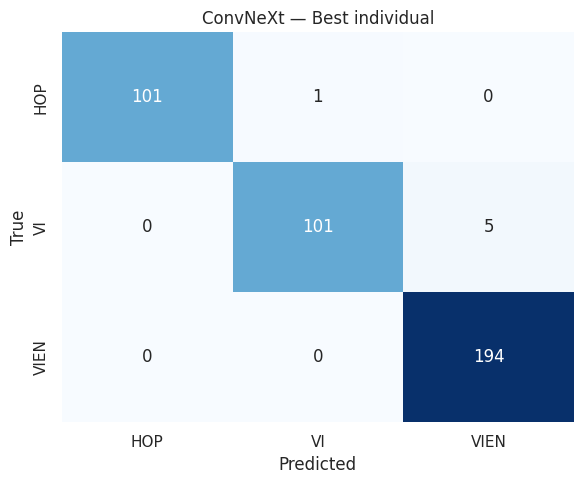

Test: DenseNet / Best individual:   0%|          | 0/17 [00:00<?, ?it/s]

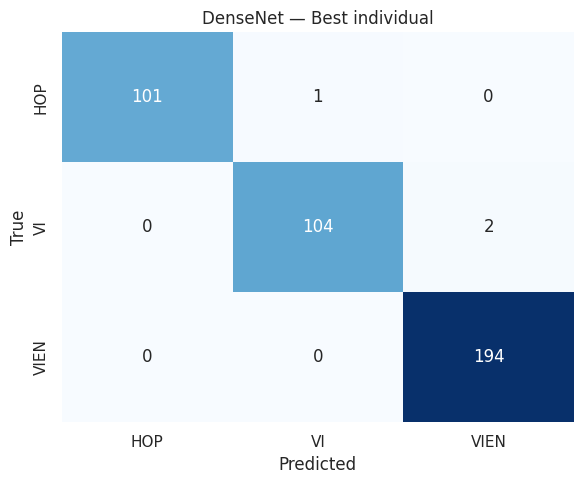

Test: ResNet / Best individual:   0%|          | 0/13 [00:00<?, ?it/s]

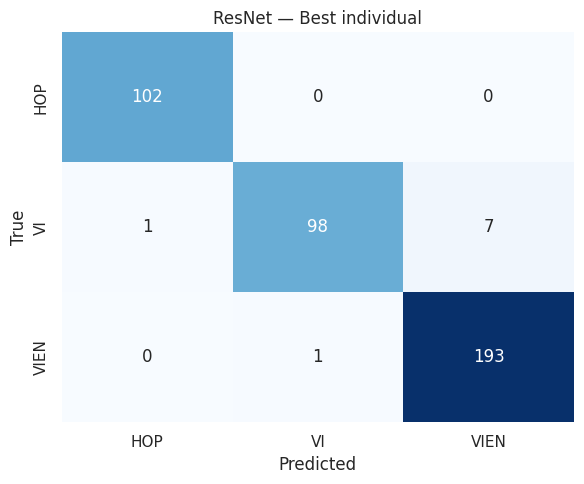

Test: MobileNet / Best individual:   0%|          | 0/9 [00:00<?, ?it/s]

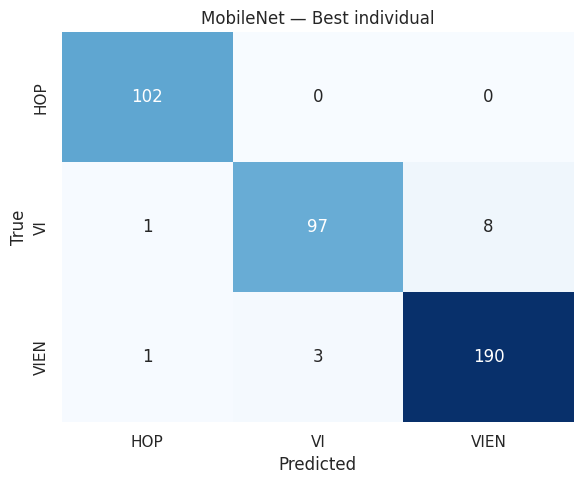

Test: SwinT / Best individual:   0%|          | 0/26 [00:00<?, ?it/s]

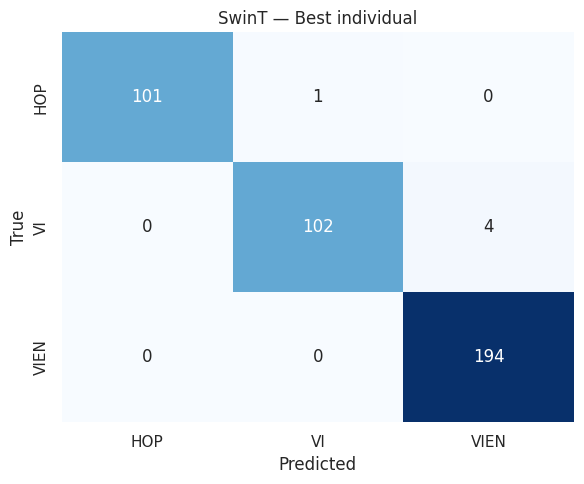

Test: ConvNeXt / Uniform soup:   0%|          | 0/17 [00:00<?, ?it/s]

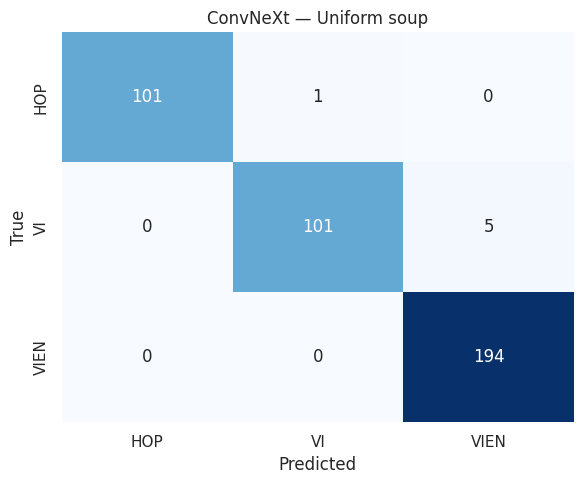

Test: ConvNeXt / Greedy soup:   0%|          | 0/17 [00:00<?, ?it/s]

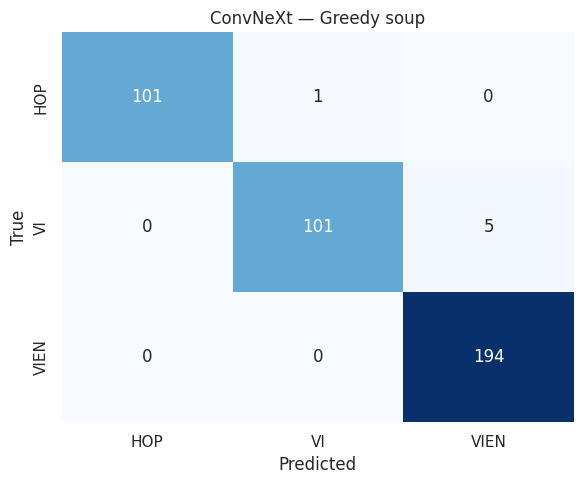

Test: DenseNet / Uniform soup:   0%|          | 0/17 [00:00<?, ?it/s]

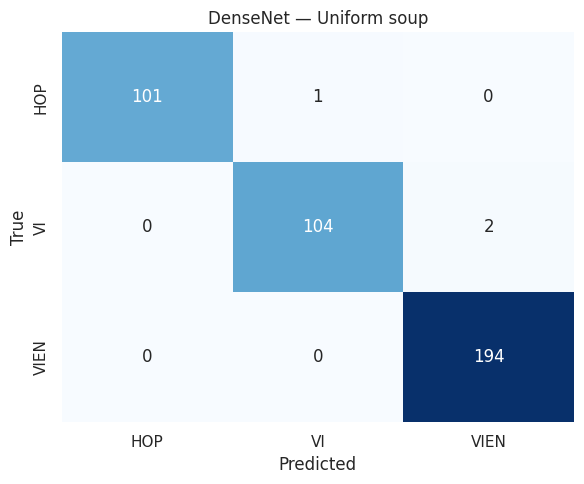

Test: DenseNet / Greedy soup:   0%|          | 0/17 [00:00<?, ?it/s]

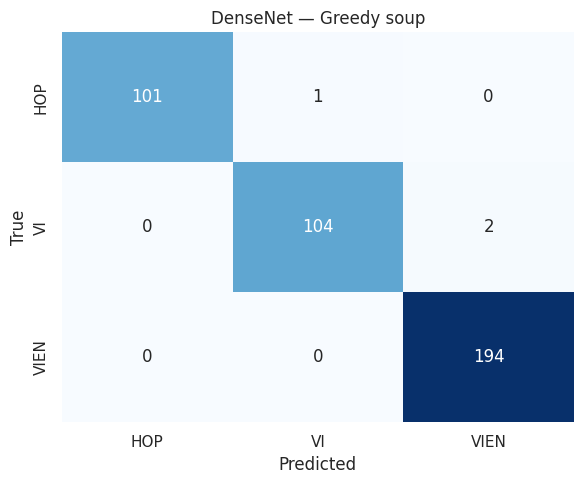

Test: ResNet / Uniform soup:   0%|          | 0/13 [00:00<?, ?it/s]

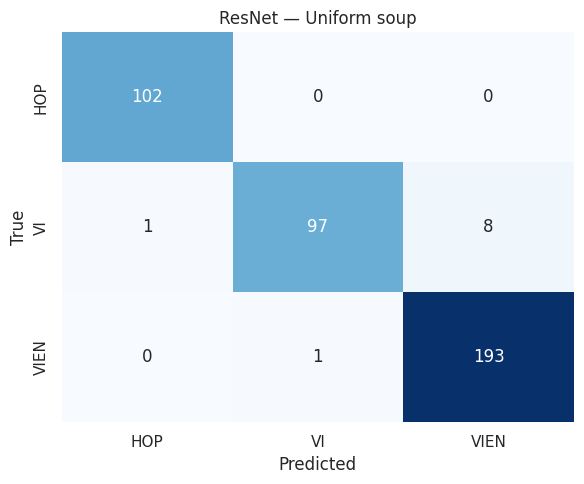

Test: ResNet / Greedy soup:   0%|          | 0/13 [00:00<?, ?it/s]

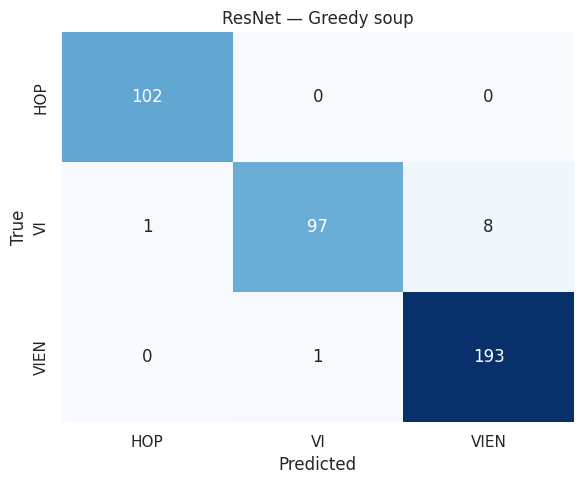

Test: MobileNet / Uniform soup:   0%|          | 0/9 [00:00<?, ?it/s]

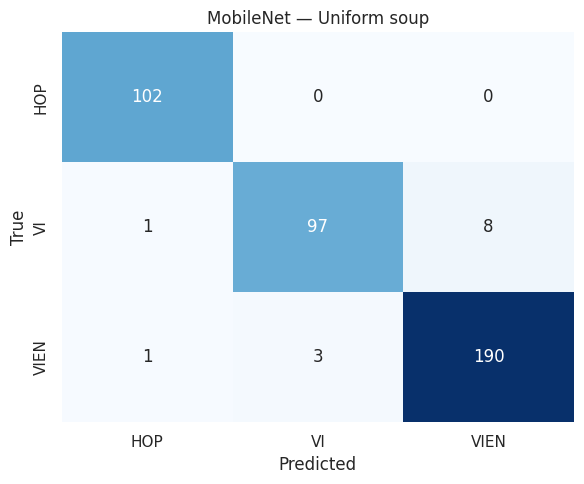

Test: MobileNet / Greedy soup:   0%|          | 0/9 [00:00<?, ?it/s]

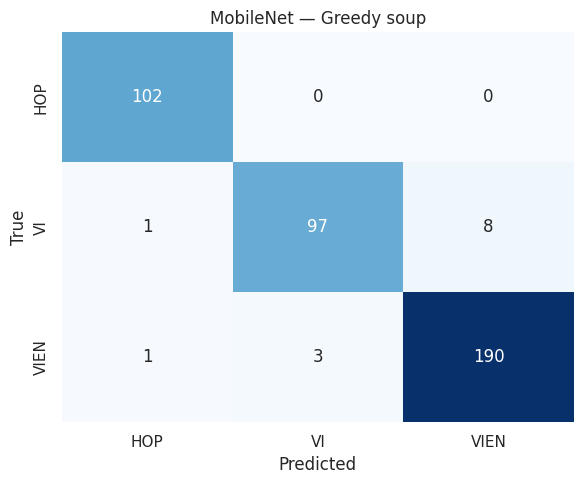

Test: SwinT / Uniform soup:   0%|          | 0/26 [00:00<?, ?it/s]

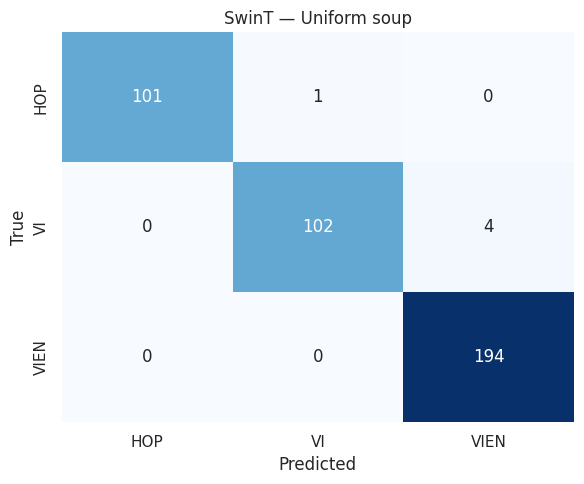

Test: SwinT / Greedy soup:   0%|          | 0/26 [00:00<?, ?it/s]

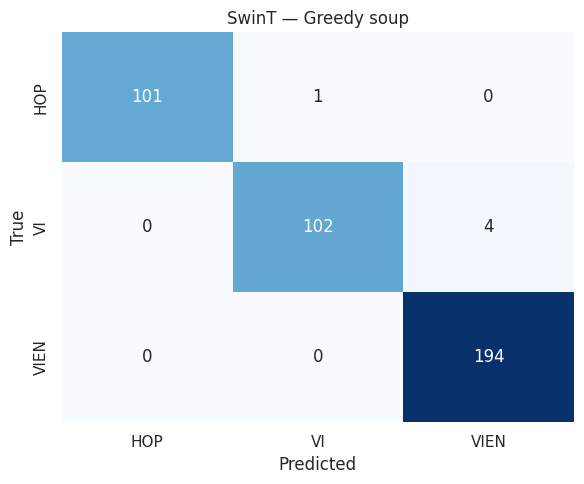

Complete cumulative results: /content/drive/MyDrive/project_outputs/results/results.csv
Detailed per-class metrics: /content/drive/MyDrive/project_outputs/results/metrics/per_class_metrics.csv


,Experiment ID,Run ID,Model,Variant,Soup Type,Number of Checkpoints,Source Checkpoints,Best Epoch,Validation Macro F1,Accuracy,...,Model State Size MB,Checkpoint Size MB,Training Peak GPU Memory MB,Inference Peak GPU Memory MB,Checkpoint Path,Predictions Path,Confusion Matrix Path,Split Fingerprint,Random Seed,Test Samples
0,20261008T152359_734636Z_seed43_6e6cf325__best_...,20261008T152359_734636Z_seed43_6e6cf325,DenseNet,Best individual,none,1,"[""/content/drive/MyDrive/project_outputs/check...",15.0,0.992701,0.992537,...,26.858601,27.118602,1713.331543,271.809570,/content/drive/MyDrive/project_outputs/checkpo...,/content/drive/MyDrive/project_outputs/results...,/content/drive/MyDrive/project_outputs/results...,5779038e7a68a089dcfa36f24c297975d250d7c3598d5b...,43,402
1,20261008T152359_734636Z_seed43_6e6cf325__greed...,20261008T152359_734636Z_seed43_6e6cf325,DenseNet,Greedy soup,greedy,5,"[""/content/drive/MyDrive/project_outputs/check...",NaN,0.992701,0.992537,...,26.858601,27.086003,1713.331543,271.809570,/content/drive/MyDrive/project_outputs/checkpo...,/content/drive/MyDrive/project_outputs/results...,/content/drive/MyDrive/project_outputs/results...,5779038e7a68a089dcfa36f24c297975d250d7c3598d5b...,43,402
2,20261008T152359_734636Z_seed43_6e6cf325__unifo...,20261008T152359_734636Z_seed43_6e6cf325,DenseNet,Uniform soup,uniform,5,"[""/content/drive/MyDrive/project_outputs/check...",NaN,0.992701,0.992537,...,26.858601,27.086702,1713.331543,271.809570,/content/drive/MyDrive/project_outputs/checkpo...,/content/drive/MyDrive/project_outputs/results...,/content/drive/MyDrive/project_outputs/results...,5779038e7a68a089dcfa36f24c297975d250d7c3598d5b...,43,402
3,20261008T155841_087592Z_seed43_3861d59f__greed...,20261008T155841_087592Z_seed43_3861d59f,SwinT,Greedy soup,greedy,5,"[""/content/drive/MyDrive/project_outputs/check...",NaN,0.995127,0.987562,...,105.206623,105.262948,1534.122070,353.111328,/content/drive/MyDrive/project_outputs/checkpo...,/content/drive/MyDrive/project_outputs/results...,/content/drive/MyDrive/project_outputs/results...,5779038e7a68a089dcfa36f24c297975d250d7c3598d5b...,43,402
4,20261008T155841_087592Z_seed43_3861d59f__unifo...,20261008T155841_087592Z_seed43_3861d59f,SwinT,Uniform soup,uniform,5,"[""/content/drive/MyDrive/project_outputs/check...",NaN,0.995127,0.987562,...,105.206623,105.263130,1534.122070,353.111328,/content/drive/MyDrive/project_outputs/checkpo...,/content/drive/MyDrive/project_outputs/results...,/content/drive/MyDrive/project_outputs/results...,5779038e7a68a089dcfa36f24c297975d250d7c3598d5b...,43,402
5,20261008T155841_087592Z_seed43_3861d59f__best_...,20261008T155841_087592Z_seed43_3861d59f,SwinT,Best individual,none,1,"[""/content/drive/MyDrive/project_outputs/check...",14.0,0.995127,0.987562,...,105.206623,105.271556,1534.122070,353.111328,/content/drive/MyDrive/project_outputs/checkpo...,/content/drive/MyDrive/project_outputs/results...,/content/drive/MyDrive/project_outputs/results...,5779038e7a68a089dcfa36f24c297975d250d7c3598d5b...,43,402
6,20261008T151526_044402Z_seed43_29021323__best_...,20261008T151526_044402Z_seed43_29021323,ConvNeXt,Best individual,none,1,"[""/content/drive/MyDrive/project_outputs/check...",9.0,0.995127,0.985075,...,106.134167,106.199779,1894.540039,354.092773,/content/drive/MyDrive/project_outputs/checkpo...,/content/drive/MyDrive/project_outputs/results...,/content/drive/MyDrive/project_outputs/results...,5779038e7a68a089dcfa36f24c297975d250d7c3598d5b...,43,402
7,20261008T151526_044402Z_seed43_29021323__unifo...,20261008T151526_044402Z_seed43_29021323,ConvNeXt,Uniform soup,uniform,5,"[""/content/drive/MyDrive/project_outputs/check...",NaN,0.992679,0.985075,...,106.134167,106.190246,1894.540039,354.592773,/content/drive/MyDrive/project_outputs/checkpo...,/content/drive/MyDrive/project_outputs/results...,/content/drive/MyDrive/project_outputs/results...,5779038e7a68a089dcfa36f24c297975d250d7c3598d5b...,43,402
8,20261008T151526_044402Z_seed43_29021323__greed...,

In [22]:
RESULTS_CSV = RESULTS_ROOT / "results.csv"
PER_CLASS_CSV = METRICS_ROOT / "per_class_metrics.csv"
experiment_specs = build_final_experiment_specs()
current_experiment_ids = {spec["experiment_id"] for spec in experiment_specs}

if RESULTS_CSV.exists():
    all_results_df = pd.read_csv(RESULTS_CSV)
else:
    all_results_df = pd.DataFrame()
if PER_CLASS_CSV.exists():
    all_per_class_df = pd.read_csv(PER_CLASS_CSV)
else:
    all_per_class_df = pd.DataFrame()

completed_ids = set(all_results_df.get("Experiment ID", pd.Series(dtype=str)).astype(str))
new_result_rows: List[Dict[str, Any]] = []
new_per_class_rows: List[pd.DataFrame] = []

for experiment_spec in experiment_specs:
    if experiment_spec["experiment_id"] in completed_ids:
        print(f"Skipping already evaluated test experiment: {experiment_spec['experiment_id']}")
        continue
    result_row, per_class_rows = evaluate_on_test(experiment_spec)
    new_result_rows.append(result_row)
    new_per_class_rows.append(per_class_rows)

if new_result_rows:
    new_results_df = pd.DataFrame(new_result_rows)
    all_results_df = pd.concat([all_results_df, new_results_df], ignore_index=True, sort=False)
    all_results_df = all_results_df.drop_duplicates("Experiment ID", keep="first")
    all_results_df.to_csv(RESULTS_CSV, index=False)
if new_per_class_rows:
    new_per_class_df = pd.concat(new_per_class_rows, ignore_index=True)
    all_per_class_df = pd.concat([all_per_class_df, new_per_class_df], ignore_index=True, sort=False)
    all_per_class_df = all_per_class_df.drop_duplicates(["Experiment ID", "Class"], keep="first")
    all_per_class_df.to_csv(PER_CLASS_CSV, index=False)

if all_results_df.empty:
    raise RuntimeError("No test results are available.")
current_results_df = all_results_df[all_results_df["Experiment ID"].isin(current_experiment_ids)].copy()
current_per_class_df = all_per_class_df[all_per_class_df["Experiment ID"].isin(current_experiment_ids)].copy()

print(f"Complete cumulative results: {RESULTS_CSV}")
print(f"Detailed per-class metrics: {PER_CLASS_CSV}")
display(current_results_df.sort_values("Macro F1", ascending=False).reset_index(drop=True))

## 16. Runtime Analysis

Training time includes training, validation, scheduler work, and checkpoint writes within the training loop. Inference time is synchronized forward-pass time. Parameter-state size is computed from the state dictionary. If `SAVE_OPTIMIZER_STATE=True`, individual training checkpoints are larger because they also contain AdamW and scheduler state.

In [23]:
runtime_columns = [
    "Model", "Variant", "Training Time", "Avg Epoch Time", "Inference Time",
    "Inference Time/Image", "Num Parameters", "Model State Size MB",
    "Checkpoint Size MB", "Training Peak GPU Memory MB", "Inference Peak GPU Memory MB",
]
display(current_results_df[runtime_columns].sort_values("Inference Time/Image"))

,Model,Variant,Training Time,Avg Epoch Time,Inference Time,Inference Time/Image,Num Parameters,Model State Size MB,Checkpoint Size MB,Training Peak GPU Memory MB,Inference Peak GPU Memory MB
41,MobileNet,Uniform soup,592.802380,39.413292,0.274786,0.000684,4205875,16.137569,16.229131,1178.135742,276.165039
33,MobileNet,Best individual,592.802380,39.413292,0.312940,0.000778,4205875,16.137569,16.242381,1178.135742,276.165039
42,MobileNet,Greedy soup,592.802380,39.413292,0.370451,0.000922,4205875,16.137569,16.228827,1178.135742,276.165039
39,ResNet,Uniform soup,689.436683,40.248443,0.652376,0.001623,23514179,89.902515,89.997037,1772.001953,348.135742
32,ResNet,Best individual,689.436683,40.248443,0.674353,0.001677,23514179,89.902515,90.005015,1772.001953,348.135742
40,ResNet,Greedy soup,689.436683,40.248443,0.758641,0.001887,23514179,89.902515,89.996604,1772.001953,348.135742
36,ConvNeXt,Greedy soup,511.298555,42.231447,0.870253,0.002165,27822435,106.134167,106.189822,1894.540039,354.592773
38,DenseNet,Greedy soup,790.659583,43.728107,1.151824,0.002865,6956931,26.858601,27.086003,1713.331543,271.809570
31,DenseNet,Best individual,790.659583,43.728107,1.179500,0.002934,6956931,26.858601,27.118602,1713.331543,271.809570
35,ConvNeXt,Uniform soup,511.298555,42.231447,1.179765,0.002935,27822435,106.134167,106.190246,1894.540039,354.592773


## 17. Visualization of Results

The primary comparison metric is test macro F1; accuracy is shown as context. A second chart compares synchronized inference time per image. Confusion matrices were saved during evaluation.

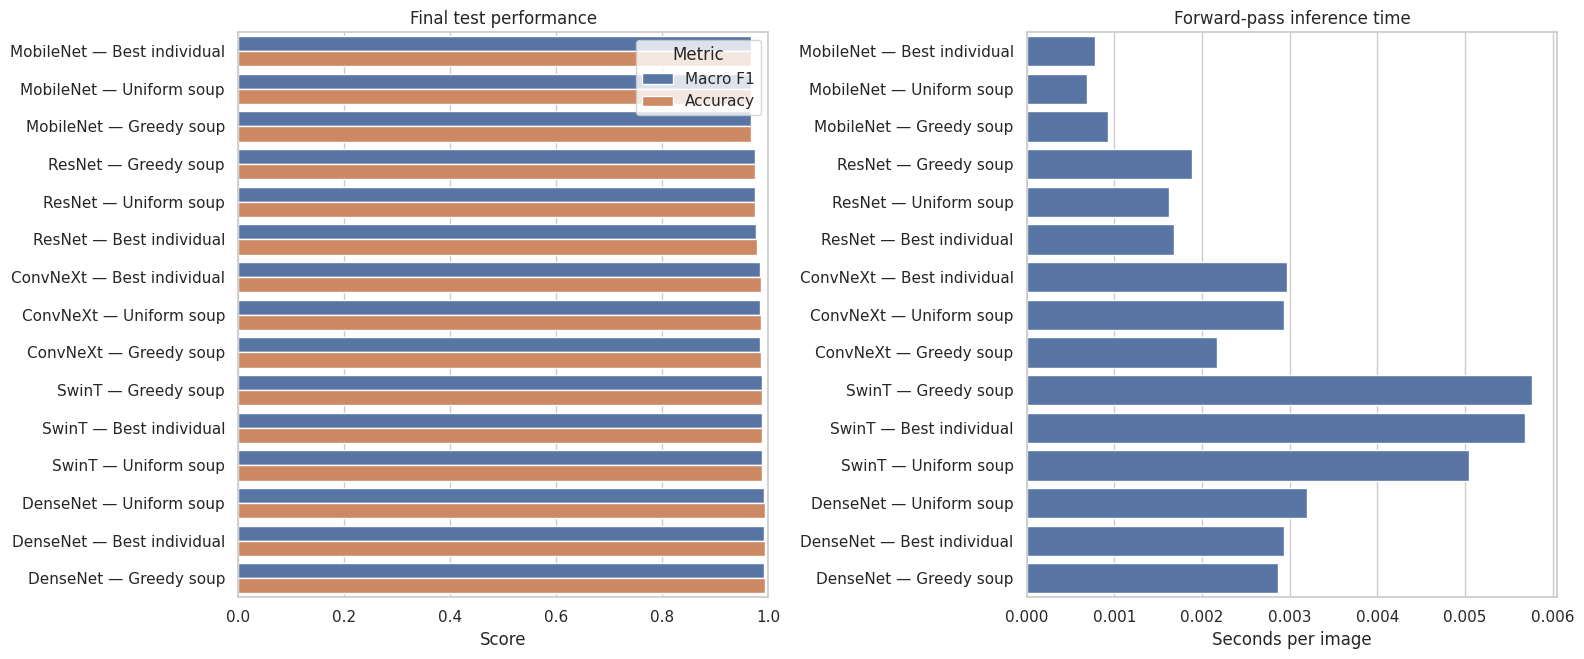

In [24]:
def plot_final_comparisons(results: pd.DataFrame) -> None:
    plotting = results.copy()
    plotting["Display Name"] = plotting["Model"] + " — " + plotting["Variant"]
    plotting = plotting.sort_values("Macro F1", ascending=True)

    fig, axes = plt.subplots(1, 2, figsize=(16, max(6, 0.45 * len(plotting))))
    metric_plot = plotting.melt(
        id_vars="Display Name", value_vars=["Macro F1", "Accuracy"],
        var_name="Metric", value_name="Score"
    )
    sns.barplot(data=metric_plot, y="Display Name", x="Score", hue="Metric", ax=axes[0])
    axes[0].set(title="Final test performance", xlabel="Score", ylabel="")
    axes[0].set_xlim(0, 1)

    sns.barplot(data=plotting, y="Display Name", x="Inference Time/Image", ax=axes[1], color="#4C72B0")
    axes[1].set(title="Forward-pass inference time", xlabel="Seconds per image", ylabel="")
    fig.tight_layout()
    fig.savefig(FIGURE_ROOT / "final_model_comparison.png", dpi=170, bbox_inches="tight")
    plt.show()

plot_final_comparisons(current_results_df)

## 18. Save Results to CSV

The cumulative main table is stored at the required `results/results.csv`; detailed per-class metrics are under `results/metrics/per_class_metrics.csv`. Prediction probabilities, JSON classification reports, confusion matrices, split metadata, and training histories are also persisted.

In [25]:
# Re-save in a stable, human-friendly column order while retaining any additional columns.
preferred_columns = [
    "Experiment ID", "Run ID", "Model", "Variant", "Soup Type", "Number of Checkpoints",
    "Source Checkpoints", "Best Epoch", "Validation Macro F1", "Accuracy", "Precision", "Recall", "F1",
    "Macro Precision", "Macro Recall", "Macro F1", "Weighted Precision", "Weighted Recall", "Weighted F1",
    "Training Time", "Avg Epoch Time", "Soup Construction Time", "Inference Time", "Inference Time/Image",
    "Num Parameters", "Model State Size MB", "Checkpoint Size MB", "Training Peak GPU Memory MB",
    "Inference Peak GPU Memory MB", "Checkpoint Path", "Predictions Path", "Confusion Matrix Path",
    "Split Fingerprint", "Random Seed", "Test Samples",
]
ordered_columns = [column for column in preferred_columns if column in all_results_df.columns]
ordered_columns += [column for column in all_results_df.columns if column not in ordered_columns]
all_results_df = all_results_df[ordered_columns]
all_results_df.to_csv(RESULTS_CSV, index=False)
all_per_class_df.to_csv(PER_CLASS_CSV, index=False)
print(f"Saved {len(all_results_df)} experiment rows to {RESULTS_CSV}")
print(f"Saved {len(all_per_class_df)} per-class rows to {PER_CLASS_CSV}")

Saved 45 experiment rows to /content/drive/MyDrive/project_outputs/results/results.csv
Saved 135 per-class rows to /content/drive/MyDrive/project_outputs/results/metrics/per_class_metrics.csv


## 19. Final Model Comparison

This table emphasizes macro F1 and per-class behavior. The best checkpoint and soups are directly comparable because they use the same split, preprocessing, test protocol, and seed.

In [26]:
comparison_columns = [
    "Model", "Variant", "Best Epoch", "Accuracy", "Macro Precision", "Macro Recall", "Macro F1",
    "Weighted F1", "Inference Time/Image", "Num Parameters", "Number of Checkpoints", "Checkpoint Path",
]
final_comparison = current_results_df[comparison_columns].sort_values("Macro F1", ascending=False).reset_index(drop=True)
display(final_comparison)

print("Per-class metrics for current experiments:")
display(current_per_class_df.sort_values(["Model", "Variant", "Class"]).reset_index(drop=True))

,Model,Variant,Best Epoch,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Inference Time/Image,Num Parameters,Number of Checkpoints,Checkpoint Path
0,DenseNet,Best individual,15.0,0.992537,0.993424,0.990443,0.991909,0.992526,0.002934,6956931,1,/content/drive/MyDrive/project_outputs/checkpo...
1,DenseNet,Greedy soup,NaN,0.992537,0.993424,0.990443,0.991909,0.992526,0.002865,6956931,5,/content/drive/MyDrive/project_outputs/checkpo...
2,DenseNet,Uniform soup,NaN,0.992537,0.993424,0.990443,0.991909,0.992526,0.003197,6956931,5,/content/drive/MyDrive/project_outputs/checkpo...
3,SwinT,Greedy soup,NaN,0.987562,0.990030,0.984153,0.986982,0.987518,0.005763,27521661,5,/content/drive/MyDrive/project_outputs/checkpo...
4,SwinT,Uniform soup,NaN,0.987562,0.990030,0.984153,0.986982,0.987518,0.005045,27521661,5,/content/drive/MyDrive/project_outputs/checkpo...
5,SwinT,Best individual,14.0,0.987562,0.990030,0.984153,0.986982,0.987518,0.005680,27521661,1,/content/drive/MyDrive/project_outputs/checkpo...
6,ConvNeXt,Best individual,9.0,0.985075,0.988357,0.981009,0.984502,0.985004,0.002973,27822435,1,/content/drive/MyDrive/project_outputs/checkpo...
7,ConvNeXt,Uniform soup,NaN,0.985075,0.988357,0.981009,0.984502,0.985004,0.002935,27822435,5,/content/drive/MyDrive/project_outputs/checkpo...
8,ConvNeXt,Greedy soup,NaN,0.985075,0.988357,0.981009,0.984502,0.985004,0.002165,27822435,3,/content/drive/MyDrive/project_outputs/checkpo...
9,ResNet,Best individual,16.0,0.977612,0.981730,0.973125,0.976972,0.977387,0.001677,23514179,1,/content/drive/MyDrive/project_outputs/checkpo...


Per-class metrics for current experiments:


,Experiment ID,Model,Variant,Class,Precision,Recall,F1,Support
0,20261008T151526_044402Z_seed43_29021323__best_...,ConvNeXt,Best individual,HOP,1.000000,0.990196,0.995074,102
1,20261008T151526_044402Z_seed43_29021323__best_...,ConvNeXt,Best individual,VI,0.990196,0.952830,0.971154,106
2,20261008T151526_044402Z_seed43_29021323__best_...,ConvNeXt,Best individual,VIEN,0.974874,1.000000,0.987277,194
3,20261008T151526_044402Z_seed43_29021323__greed...,ConvNeXt,Greedy soup,HOP,1.000000,0.990196,0.995074,102
4,20261008T151526_044402Z_seed43_29021323__greed...,ConvNeXt,Greedy soup,VI,0.990196,0.952830,0.971154,106
5,20261008T151526_044402Z_seed43_29021323__greed...,ConvNeXt,Greedy soup,VIEN,0.974874,1.000000,0.987277,194
6,20261008T151526_044402Z_seed43_29021323__unifo...,ConvNeXt,Uniform soup,HOP,1.000000,0.990196,0.995074,102
7,20261008T151526_044402Z_seed43_29021323__unifo...,ConvNeXt,Uniform soup,VI,0.990196,0.952830,0.971154,106
8,20261008T151526_044402Z_seed43_29021323__unifo...,ConvNeXt,Uniform soup,VIEN,0.974874,1.000000,0.987277,194
9,20261008T152359_734636Z_seed43_6e6cf325__best_...,DenseNet,Best individual,HOP,1.000000,0.990196,0.995074,102


## 20. Conclusions

The cell below generates a concise, data-driven conclusion. Prefer macro F1 and the weakest per-class F1 over accuracy alone when choosing a deployment model. Also consider latency, memory, and checkpoint size. A soup has the same architecture and inference cost as its ingredients; its checkpoint count affects construction/storage provenance, not forward-pass cost.

In [27]:
best_row = current_results_df.loc[current_results_df["Macro F1"].idxmax()]
weakest_class_row = current_per_class_df.loc[current_per_class_df["F1"].idxmin()]
print(
    f"Best current experiment by test macro F1: {best_row['Model']} — {best_row['Variant']} "
    f"(macro F1={best_row['Macro F1']:.4f}, accuracy={best_row['Accuracy']:.4f})."
)
print(
    f"Lowest observed per-class F1 among current experiments: class {weakest_class_row['Class']} "
    f"for {weakest_class_row['Model']} — {weakest_class_row['Variant']} "
    f"(F1={weakest_class_row['F1']:.4f})."
)
print(f"Artifacts are available under: {RESULTS_ROOT}")

Best current experiment by test macro F1: DenseNet — Best individual (macro F1=0.9919, accuracy=0.9925).
Lowest observed per-class F1 among current experiments: class VI for MobileNet — Best individual (F1=0.9417).
Artifacts are available under: /content/drive/MyDrive/project_outputs/results
